# Z potential: committor from many short trajectories

The 2D Brownian Z potential of the staple run `sim_istarz_br_g10` (toytis `sjoelbak_angle`, Lx = 0.3, 45° ridge; overdamped, γ = 10, kT = 0.05, dt = 0.002; A: y ≤ 0.05, B: y ≥ 0.85, y = order parameter).

**Part 1** (original `optimalrcs-cupy`): take a saved first-try committor (any `committor.npz` with the frames and their q), pick start frames evenly over bins of its natural coordinate q_n (or of q), run many short trajectories of the real dynamics from them, and fit NPNEq (`CommittorNE`) on those trajectories. The new trajectories are plain dynamics (no path selection, no weights), so the fit is unbiased whatever the start frames are; the bins only decide where the data are. The result can be saved in the same format and used as the next first try.

**Part 2** (Elias' TIS version of the library, restart the kernel first): read the staple paths and fit the committor on them; it saves the `committor.npz` that part 1 can start from.

## Part 1: short trajectories from a first-try committor

### Imports (original optimalrcs-cupy)

In [1]:
import os
import sys
import time

import numpy as np
import cupy as cp
import matplotlib.pyplot as plt

plt.rc('font', size=14)          # controls default text sizes
plt.rc('axes', titlesize=16)     # fontsize of the axes title
plt.rc('axes', labelsize=16)     # fontsize of the x and y labels
plt.rc('xtick', labelsize=14)    # fontsize of the tick labels
plt.rc('ytick', labelsize=14)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize

# ORIG_LIB = '/home/staff7/fbsskr/Notebooks/optimalrcs-cupy/'      # the original optimalrcs-cupy
ORIG_LIB = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy'
sys.path.append(ORIG_LIB)
import optimalrcs, metrics, plots

FIG = 'figures_by_potential/2d_zpot/brownian_g10/short_trajectories'                               # figures and data of this notebook
os.makedirs(FIG, exist_ok=True)

def show(call, name):
    """Run a plotting call of the library (which calls plt.show itself), save the figure, then show it."""
    plt_show = plt.show
    plt.show = lambda *a, **k: None
    try:
        call()
    finally:
        plt.show = plt_show
    plt.gcf().savefig(f'{FIG}/{name}.png', dpi=100, bbox_inches='tight')
    plt.show()

### The Z potential and its dynamics

`force(y, x)` is the force of toytis' `RectangularGridWithAngledBarrierPotential(Lx=0.3, angle=45)` term by term (walls, the tilted cosine ridge, the cosine wells of A and B, the slope between them and gravity), on GPU arrays. `potential(y, x)` is its effective potential (the class' `potential` plus gravity × y, so that force = −∇V). If toytis can be imported, the force is checked against the class.

The dynamics is the toytis overdamped update: y ← y + dt/γ F_y + σ ξ, the same for x, σ = √(2 kT dt / γ), absorption checked every step.

In [2]:
kT, gamma_md, dt = 0.05, 10.0, 0.002      # dynamics of sim_istarz_br_g10
lambda_A, lambda_B = 0.05, 0.85            # A: y <= lambda_A, B: y >= lambda_B

# parameters of the potential (toytis defaults, Lx = 0.3, angle = 45 degrees)
Lx, Ly, k_wall = 0.3, 0.9, 2000.0
A_ridge, L_ridge = 0.3, 0.2                # ridge height and length scale (half-width L/4)
slope_r = -np.tan(np.radians(45.0))        # the ridge line y = slope_r * x + b passes through (x, y) = (Lx/2, 0.45)
b_ridge = 0.45 - slope_r * Lx / 2
wells = [(0.025, -0.15, 0.2), (0.875, -0.15, 0.2)]   # (centre y, amplitude, length scale) of the wells of A and B
slope_start, slope_end, slope_strength = 0.1, 0.825, 0.2
gravity = 0.2

def force(y, x, xp=cp):
    """Force (F_y, F_x) of the Z potential at arrays (y, x)."""
    fx = xp.where(x < 0, -k_wall * x, xp.where(x > Lx, -k_wall * (x - Lx), 0.0))        # walls
    fy = xp.where(y < 0, -k_wall * y, xp.where(y > Ly, -k_wall * (y - Ly), 0.0))
    norm = np.sqrt(slope_r ** 2 + 1)                                                     # ridge
    D = xp.abs(slope_r * x - y + b_ridge) / norm
    dV_dD = xp.where(D < L_ridge / 4, -2 * np.pi * A_ridge / L_ridge * xp.sin(2 * np.pi * D / L_ridge), 0.0)
    side = xp.sign(y - slope_r * x - b_ridge)
    fx = fx + side * dV_dD * slope_r / norm
    fy = fy - side * dV_dD / norm
    for yc, amp, ell in wells:                                                           # wells of A and B
        Dw = xp.abs(y - yc)
        fy = fy + xp.where(Dw < ell / 4, amp * 2 * np.pi / ell * xp.sin(2 * np.pi * Dw / ell) * xp.sign(y - yc), 0.0)
    inside = (y >= slope_start) & (y <= slope_end)                                       # slope and gravity
    fy = fy + xp.where(inside, -slope_strength / (slope_end - slope_start), 0.0) - gravity
    return fy, fx

def potential(y, x, xp=np):
    """Effective potential of the Z potential (force = -grad V)."""
    v = xp.where(x < 0, 0.5 * k_wall * x ** 2, xp.where(x > Lx, 0.5 * k_wall * (x - Lx) ** 2, 0.0))
    v = v + xp.where(y < 0, 0.5 * k_wall * y ** 2, xp.where(y > Ly, 0.5 * k_wall * (y - Ly) ** 2, 0.0))
    D = xp.abs(slope_r * x - y + b_ridge) / np.sqrt(slope_r ** 2 + 1)
    v = v + xp.where(D < L_ridge / 4, A_ridge * xp.cos(2 * np.pi * D / L_ridge), 0.0)
    for yc, amp, ell in wells:
        Dw = xp.abs(y - yc)
        v = v + xp.where(Dw < ell / 4, amp * xp.cos(2 * np.pi * Dw / ell), 0.0)
    v = v + xp.where(y < slope_start, 0.0, xp.where(y <= slope_end, slope_strength * (y - slope_start) / (slope_end - slope_start), slope_strength))
    return v + gravity * y

# check against the toytis class, if it can be imported
TOYTIS = '/home/staff7/fbsskr/Notebooks/Students/elias/toytis'
try:
    sys.path.insert(0, TOYTIS)
    from potentials.sjoelbak_angle import RectangularGridWithAngledBarrierPotential
    pot = RectangularGridWithAngledBarrierPotential(Lx=0.3, angle=45)
    pts = np.random.default_rng(1).uniform([-0.02, -0.02], [0.92, 0.32], size=(300, 2))
    f_here = np.column_stack([f.get() for f in force(cp.asarray(pts[:, 0]), cp.asarray(pts[:, 1]))])
    f_class = np.array([pot.potential_and_force((p, np.zeros(2)))[1] for p in pts])
    v_here = potential(pts[:, 0], pts[:, 1])
    v_class = np.array([pot.effective_potential((p, np.zeros(2))) for p in pts])
    print('force and potential agree with the toytis class:', np.allclose(f_here, f_class, atol=1e-9), np.allclose(v_here, v_class, atol=1e-9))
except ImportError:
    print('toytis not found: force and potential not checked against the class')

gy, gx = np.linspace(-0.02, 0.92, 189), np.linspace(-0.02, 0.32, 69)
V = potential(*np.meshgrid(gy, gx, indexing='ij'))
V_levels = np.arange(0, 12.5, 1.0)
def draw_potential(ax):
    ax.contour(gy, gx, ((V - V.min()) / kT).T, levels=V_levels, colors='0.6', linewidths=0.5)
    for lam in (lambda_A, lambda_B):
        ax.axvline(lam, color='k', lw=1)
    ax.set(xlabel='y (order parameter)', ylabel='x', xlim=(-0.02, 0.92), ylim=(-0.02, 0.32))

force and potential agree with the toytis class: True True


### The first-try committor

Any `committor.npz` with the frames and their committor: `X_all` (columns y, x), `r` (or `q_fit`), and for q_n also `i_traj`, `t_traj` (and `path_weights` if the frames are path data). Part 2 saves such a file; so do `load_tis_data_cupy.py` and the staple notebooks.

`BIN_ON = 'qn'`: start frames evenly over bins of the natural coordinate q_n of the first try (`plots.transform_q2qn`): equal steps in q_n are steps of equal difficulty for the dynamics, so the starts are spread over the transition region instead of piling up where the paths spend their time. `BIN_ON = 'q'`: bins of q itself.

/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/istarz_br_g10/committor.npz: 20,848,384 frames, 20,839,049 outside A and B
frames per bin of qn: [3539391 2422879 1885956 1237109  425448   30046    4669   10968  164466
  630507  836590  776495  722851  715199  695248  686674  673363  653813
  631798  606107  581760  573410  549437  473753  414151  370621  276458
  157568   63393   28921]


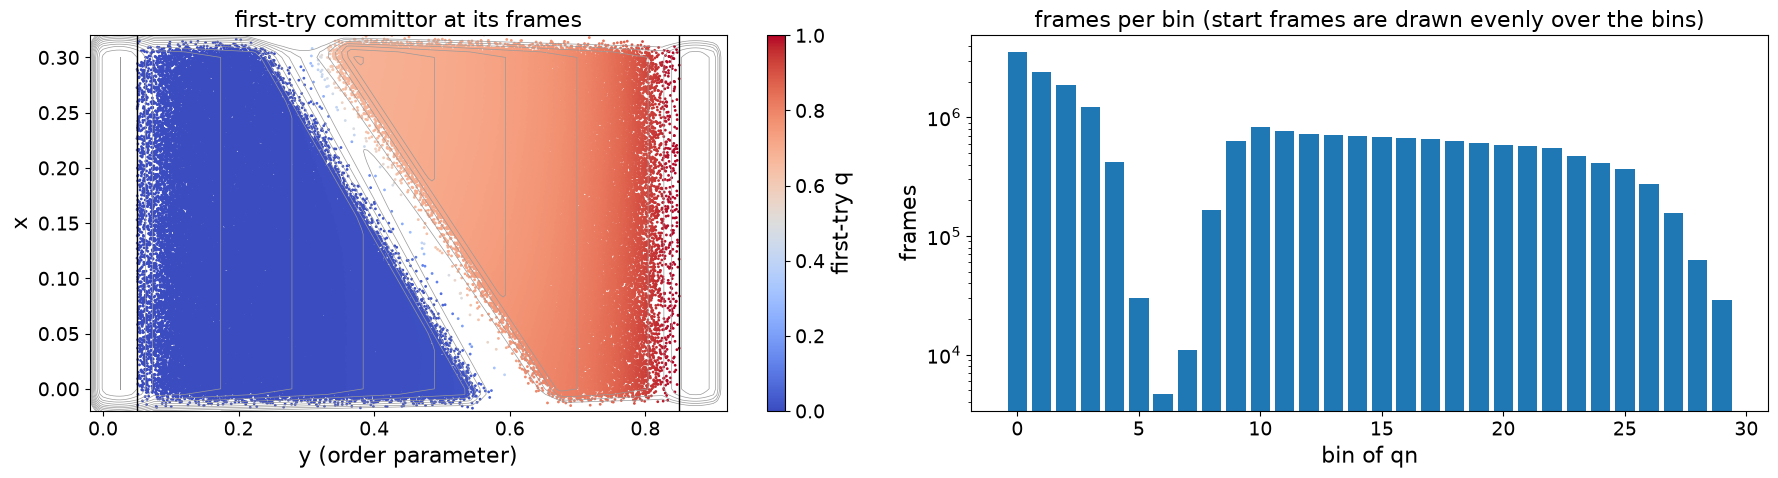

In [3]:
FIRST_TRY_NPZ = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/brownian_g10/staple/original/committor.npz'
BIN_ON = 'qn'              # 'qn' or 'q'
N_BINS = 30

d = np.load(FIRST_TRY_NPZ)
q_first = (d['r'] if 'r' in d.files else d['q_fit']).astype(float)
y_first, x_first = d['X_all'][:, 0].astype(float), d['X_all'][:, 1].astype(float)
free_first = (y_first > lambda_A) & (y_first < lambda_B)
print(f'{FIRST_TRY_NPZ}: {len(q_first):,} frames, {free_first.sum():,} outside A and B')

if BIN_ON == 'qn':
    w_first = cp.asarray(d['path_weights']) if 'path_weights' in d.files else None
    qn_first = plots.transform_q2qn(cp.asarray(q_first), i_traj=cp.asarray(d['i_traj']), t_traj=cp.asarray(d['t_traj']),
                                    w_traj=w_first, dt_sim=dt)
    coord = qn_first / qn_first.max()
else:
    coord = q_first
bin_first = np.clip((coord * N_BINS).astype(int), 0, N_BINS - 1)
n_per_bin = np.bincount(bin_first[free_first], minlength=N_BINS)
print(f'frames per bin of {BIN_ON}:', n_per_bin)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5))
show_frames = np.random.default_rng(0).choice(np.flatnonzero(free_first), size=min(200_000, free_first.sum()), replace=False)
sc = ax1.scatter(y_first[show_frames], x_first[show_frames], c=q_first[show_frames], s=1, cmap='coolwarm', vmin=0, vmax=1)
draw_potential(ax1)
fig.colorbar(sc, ax=ax1, label='first-try q')
ax1.set_title('first-try committor at its frames')
ax2.bar(np.arange(N_BINS), n_per_bin)
ax2.set(yscale='log', xlabel=f'bin of {BIN_ON}', ylabel='frames', title='frames per bin (start frames are drawn evenly over the bins)')
fig.tight_layout()
fig.savefig(f'{FIG}/first_try.png', dpi=100, bbox_inches='tight')
plt.show()

### Many short trajectories

`N_TRAJ` start frames, `N_TRAJ / N_BINS` per bin (fewer if a bin has fewer frames), one trajectory of at most `L` steps from each, stopped when it reaches A or B. All trajectories run at once on the GPU; a stopped trajectory is frozen and its later frames are not used.

19980 trajectories of up to 300 steps in 0.2 s; 12% reached A or B
5,527,690 frames; 278 in A, 2051 in B


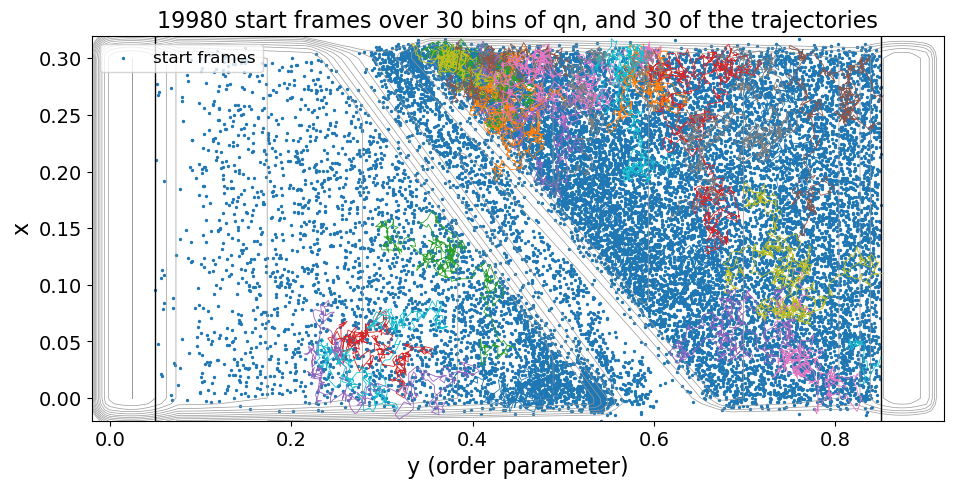

In [4]:
N_TRAJ = 20_000
L = 300                    # steps per trajectory
TAG, TRAP = f'{BIN_ON}bins', 'fixed'
SEED = 0

rng = np.random.default_rng(SEED)
start = np.concatenate([rng.choice(np.flatnonzero(free_first & (bin_first == b)), size=min(N_TRAJ // N_BINS, n_per_bin[b]), replace=False)
                        for b in range(N_BINS)]) # select N_TRAJ/N_BINS random points in 30 bins of q_n

n_traj = len(start)

sigma = np.sqrt(2 * kT * dt / gamma_md)
cp.random.seed(SEED)
y_now, x_now = cp.asarray(y_first[start]), cp.asarray(x_first[start])
Y_frames, X_frames = cp.zeros((L + 1, n_traj)), cp.zeros((L + 1, n_traj))      # [step, trajectory]
Y_frames[0], X_frames[0] = y_now, x_now
last = cp.full(n_traj, L)                       # last frame of each trajectory
running = cp.ones(n_traj, bool)
t0 = time.time()
for step in range(1, L + 1):
    fy, fx = force(y_now, x_now)
    y_now = cp.where(running, y_now + dt / gamma_md * fy + sigma * cp.random.standard_normal(n_traj), y_now)
    x_now = cp.where(running, x_now + dt / gamma_md * fx + sigma * cp.random.standard_normal(n_traj), x_now)
    Y_frames[step], X_frames[step] = y_now, x_now
    absorbed = running & ((y_now <= lambda_A) | (y_now >= lambda_B))
    last = cp.where(absorbed, step, last)
    running = running & ~absorbed
last = last.get()
print(f'{n_traj} trajectories of up to {L} steps in {time.time() - t0:.1f} s; '
      f'{np.mean(last < L):.0%} reached A or B')

# one segment per trajectory: frames 0 .. last
keep = np.arange(L + 1)[None, :] <= last[:, None]                  # [trajectory, step]
y = Y_frames.get().T[keep]
x = X_frames.get().T[keep]
i_traj = np.repeat(np.arange(n_traj), last + 1)
t_traj = np.concatenate([np.arange(n + 1) for n in last]).astype(float)
first_frame = np.r_[0, np.cumsum(last + 1)[:-1]]                  # index of each start frame
del Y_frames, X_frames
print(f'{len(y):,} frames; {np.sum(y <= lambda_A)} in A, {np.sum(y >= lambda_B)} in B')
np.savez(f'{FIG}/short_traj_{BIN_ON}_n{n_traj}_L{L}.npz', y=y, x=x, i_traj=i_traj, t_traj=t_traj, start=start)

fig, ax = plt.subplots(figsize=(11, 5))
draw_potential(ax)
ax.scatter(y[first_frame], x[first_frame], s=2, c='C0', label='start frames')
for j in np.random.default_rng(1).choice(n_traj, 30, replace=False):
    ax.plot(y[i_traj == j], x[i_traj == j], lw=0.6)
ax.legend(loc='upper left')
ax.set_title(f'{n_traj} start frames over {N_BINS} bins of {BIN_ON}, and 30 of the trajectories')
fig.savefig(f'{FIG}/trajectories_{BIN_ON}_n{n_traj}_L{L}.png', dpi=100, bbox_inches='tight')
plt.show()

20000 trajectories of up to 300 steps in 0.1 s; 19% reached A or B
5,235,833 frames; 2212 in A, 1572 in B


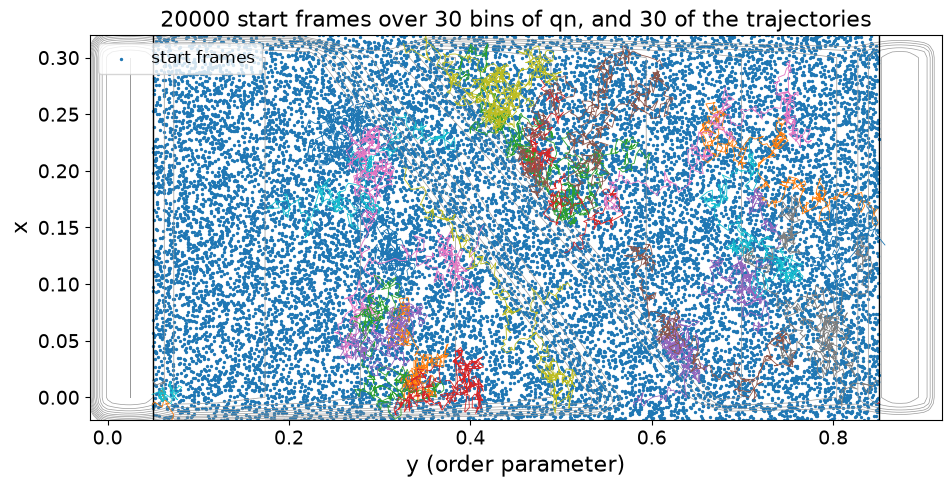

In [10]:
N_TRAJ = 20_000
L = 300                    # steps per trajectory
TAG, TRAP = 'uniformxy', 'fixed'
SEED = 0

rng = np.random.default_rng(SEED)
start = np.concatenate([rng.choice(np.flatnonzero(free_first & (bin_first == b)), size=min(N_TRAJ // N_BINS, n_per_bin[b]), replace=False)
                        for b in range(N_BINS)]) # select N_TRAJ/N_BINS random points in 30 bins of q_n
# 1. Find the continuous boundaries of your valid region
y_first, x_first = d['X_all'][:, 0].astype(float), d['X_all'][:, 1].astype(float)
free_first = (y_first > lambda_A) & (y_first < lambda_B)

x_min, x_max = x_first[free_first].min(), x_first[free_first].max()

# 2. Generate N_TRAJ fictitious (x, y) coordinates uniformly across that 2D space
x_fictitious = rng.uniform(x_min, x_max, N_TRAJ)
y_fictitious = rng.uniform(lambda_A, lambda_B, N_TRAJ)
n_traj = N_TRAJ

sigma = np.sqrt(2 * kT * dt / gamma_md)
cp.random.seed(SEED)
#y_now, x_now = cp.asarray(y_first[start]), cp.asarray(x_first[start])
y_now, x_now = cp.asarray(y_fictitious), cp.asarray(x_fictitious)
Y_frames, X_frames = cp.zeros((L + 1, n_traj)), cp.zeros((L + 1, n_traj))      # [step, trajectory]
Y_frames[0], X_frames[0] = y_now, x_now
last = cp.full(n_traj, L)                       # last frame of each trajectory
running = cp.ones(n_traj, bool)
t0 = time.time()
for step in range(1, L + 1):
    fy, fx = force(y_now, x_now)
    y_now = cp.where(running, y_now + dt / gamma_md * fy + sigma * cp.random.standard_normal(n_traj), y_now)
    x_now = cp.where(running, x_now + dt / gamma_md * fx + sigma * cp.random.standard_normal(n_traj), x_now)
    Y_frames[step], X_frames[step] = y_now, x_now
    absorbed = running & ((y_now <= lambda_A) | (y_now >= lambda_B))
    last = cp.where(absorbed, step, last)
    running = running & ~absorbed
last = last.get()
print(f'{n_traj} trajectories of up to {L} steps in {time.time() - t0:.1f} s; '
      f'{np.mean(last < L):.0%} reached A or B')

# one segment per trajectory: frames 0 .. last
keep = np.arange(L + 1)[None, :] <= last[:, None]                  # [trajectory, step]
y = Y_frames.get().T[keep]
x = X_frames.get().T[keep]
i_traj = np.repeat(np.arange(n_traj), last + 1)
t_traj = np.concatenate([np.arange(n + 1) for n in last]).astype(float)
first_frame = np.r_[0, np.cumsum(last + 1)[:-1]]                  # index of each start frame
del Y_frames, X_frames
print(f'{len(y):,} frames; {np.sum(y <= lambda_A)} in A, {np.sum(y >= lambda_B)} in B')
np.savez(f'{FIG}/short_traj_{BIN_ON}_n{n_traj}_L{L}.npz', y=y, x=x, i_traj=i_traj, t_traj=t_traj, start=start)

fig, ax = plt.subplots(figsize=(11, 5))
draw_potential(ax)
ax.scatter(y[first_frame], x[first_frame], s=2, c='C0', label='start frames')
for j in np.random.default_rng(1).choice(n_traj, 30, replace=False):
    ax.plot(y[i_traj == j], x[i_traj == j], lw=0.6)
ax.legend(loc='upper left')
ax.set_title(f'{n_traj} start frames over {N_BINS} bins of {BIN_ON}, and 30 of the trajectories')
fig.savefig(f'{FIG}/trajectories_{BIN_ON}_n{n_traj}_L{L}.png', dpi=100, bbox_inches='tight')
plt.show()

### More start-point choices: what staple TIS does to NPNEq

Staple TIS gives NPNEq pieces that start right next to an interface (forward pieces at the first frame past M, mirrored pieces at the last frame before M), whose starts are distributed as the path ensemble samples them, and whose lengths depend on the dynamics. The cells below bring in these three properties one at a time, each with plain dynamics, so each fit can be compared with the exact committor:

| Cell | Start points | Length | Trap |
|---|---|---|---|
| `intf_uniformx` | within one step before or after an interface M, uniformly over the M's and over x | fixed `L` | fixed |
| `path_starts` | the first frames of the TIS pieces (forward and mirrored), drawn with the path weights | fixed `L` | fixed |
| `path_starts_geom` | as `path_starts` | geometric, mean `L_MEAN` | Poisson |
| `path_starts_turn` | as `path_starts` | until a turn (as in toytis' [i*] moves), A or B | absorbing |

Run one of them instead of the two cells above, then the fit, comparison and save cells as before. Each sets `TAG` (file names) and `TRAP` (which trap the fit cell uses).

**Stopping at a turn.** As toytis' `turn_detected` (`pgmoves.py`): a trajectory stops when it crosses back past the interface before the last one it reached, e.g. crossings λ_{i+1}, λ_i, (any recrossings of λ_i), λ_{i+1} is a turn around λ_i. Every walker keeps the most recently crossed interface and the one crossed before it (recrossings of the same interface do not count); crossing that earlier one again is the turn. A start frame lies within one step of an interface M, as the first frame of a TIS piece, so it counts as having just crossed M, coming from the interface on its other side (as toytis does when it extends a path from a point: the direction it moves in is away from where it came from). The stop depends on the trajectory itself, as the piece ends in staple TIS do; trajectories that end in A or B stay there for the Z_q plots (`TRAP = 'absorb'`), and for the ones stopped by a turn Z_q uses q at the stop for every window that passes it (`set_stopped_traj_end`). Dropping those windows instead would keep only trajectories that had not turned yet, which biases Z_q even for the exact committor; the fit itself does not need this, since a turn is a stopping time.

**Lengths and the Poisson trap.** `set_poisson_traj_length_trap` lets every trajectory that ends in A or B continue there for an exponentially distributed number of frames, mean `L_MEAN`. That is right when every step has the same chance 1/`L_MEAN` to be the last, i.e. geometric lengths: then the length left after absorption has the same distribution whatever happened before. `draw_lengths` can be swapped for another distribution, but the trap then no longer matches: a wrong trap only biases the Z_q plots, not the fit.

In [4]:
def run_short(y0, x0, lengths, seed=0):
    """Overdamped trajectories from (y0, x0), all at once on the GPU: trajectory j runs lengths[j] steps
    or until it reaches A or B. Returns y, x, i_traj, t_traj, first_frame (one segment per trajectory)."""
    n = len(y0)
    lengths = np.asarray(lengths, int)
    L_max = int(lengths.max())
    sigma = np.sqrt(2 * kT * dt / gamma_md)
    cp.random.seed(seed)
    y_now, x_now = cp.asarray(y0, dtype=cp.float64), cp.asarray(x0, dtype=cp.float64)
    Y_frames, X_frames = cp.zeros((L_max + 1, n)), cp.zeros((L_max + 1, n))      # [step, trajectory]
    Y_frames[0], X_frames[0] = y_now, x_now
    len_gpu = cp.asarray(lengths)
    last = len_gpu.copy()                       # last frame of each trajectory
    running = len_gpu > 0
    t0 = time.time()
    for step in range(1, L_max + 1):
        fy, fx = force(y_now, x_now)
        y_now = cp.where(running, y_now + dt / gamma_md * fy + sigma * cp.random.standard_normal(n), y_now)
        x_now = cp.where(running, x_now + dt / gamma_md * fx + sigma * cp.random.standard_normal(n), x_now)
        Y_frames[step], X_frames[step] = y_now, x_now
        absorbed = running & ((y_now <= lambda_A) | (y_now >= lambda_B))
        last = cp.where(absorbed, step, last)
        running = running & ~absorbed & (step < len_gpu)
    last = last.get()
    print(f'{n} trajectories of {lengths.min()} to {L_max} steps (mean {lengths.mean():.0f}) in {time.time() - t0:.1f} s; '
          f'{np.mean(last < lengths):.0%} reached A or B')
    keep = np.arange(L_max + 1)[None, :] <= last[:, None]            # [trajectory, step]
    y_, x_ = Y_frames.get().T[keep], X_frames.get().T[keep]
    del Y_frames, X_frames
    i_traj_ = np.repeat(np.arange(n), last + 1)
    t_traj_ = np.concatenate([np.arange(k + 1) for k in last]).astype(float)
    first_frame_ = np.r_[0, np.cumsum(last + 1)[:-1]]
    print(f'{len(y_):,} frames; {np.sum(y_ <= lambda_A)} in A, {np.sum(y_ >= lambda_B)} in B')
    return y_, x_, i_traj_, t_traj_, first_frame_


INTERFACES = [0.05, 0.13, 0.21, 0.29, 0.37, 0.45, 0.53, 0.61, 0.69, 0.77, 0.85]    # of sim_istarz_br_g10
M_ALL = np.array(INTERFACES[:-1])          # the M of the ensembles 0* .. 9* (where the pieces are cut)


def path_piece_starts(path_npz):
    """First frame of every piece of TIS path data outside A and B (forward pieces: first frame past M;
    mirrored pieces: last frame before M, if the data has them), with the path weight of its piece."""
    dp = d if path_npz == FIRST_TRY_NPZ else np.load(path_npz)
    i_p, X_p, w_p = dp['i_traj'], dp['X_all'], dp['path_weights'].astype(float)
    s = np.flatnonzero(np.r_[True, i_p[1:] != i_p[:-1]])
    s = s[(X_p[s, 0] > lambda_A) & (X_p[s, 0] < lambda_B)]
    return s, X_p[s, 0].astype(float), X_p[s, 1].astype(float), w_p[s]


def show_starts(y0, title):
    """Start frames and 30 trajectories on the potential; offsets of the starts from the nearest M."""
    off = y0 - M_ALL[np.abs(y0[:, None] - M_ALL[None, :]).argmin(1)]
    print(f'start offset from the nearest M: {np.mean(off < 0):.0%} before, {np.mean(off > 0):.0%} after, '
          f'|offset| median {np.median(np.abs(off)):.4f} (one step: {np.sqrt(2 * kT * dt / gamma_md):.4f})')
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw=dict(width_ratios=[2, 1]))
    draw_potential(ax1)
    for lam in M_ALL:
        ax1.axvline(lam, color='k', lw=0.5, ls=':')
    ax1.scatter(y[first_frame], x[first_frame], s=2, c='C0', label='start frames')
    for j in np.random.default_rng(1).choice(len(first_frame), 30, replace=False):
        ax1.plot(y[i_traj == j], x[i_traj == j], lw=0.6)
    ax1.legend(loc='upper left')
    ax1.set_title(title)
    ax2.hist(off, bins=np.linspace(-0.04, 0.04, 81))
    ax2.set(xlabel='start y $-$ nearest M', ylabel='start frames', title='distance of the starts from the interfaces')
    fig.tight_layout()
    fig.savefig(f'{FIG}/trajectories_{TAG}.png', dpi=100, bbox_inches='tight')
    plt.show()

20000 trajectories of 300 to 300 steps (mean 300) in 0.1 s; 19% reached A or B
5,164,405 frames; 3228 in A, 643 in B
start offset from the nearest M: 45% before, 55% after, |offset| median 0.0022 (one step: 0.0045)


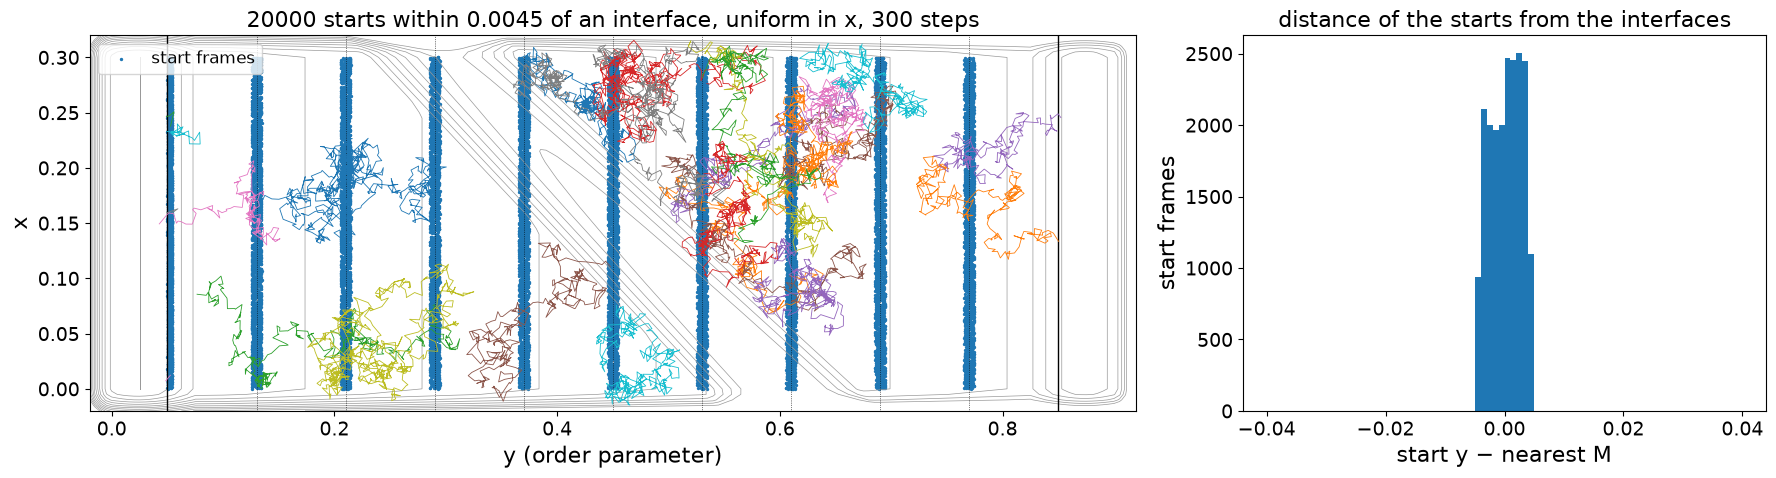

In [5]:
# Starts within one step before or after an interface M, uniformly over the M's and over x; fixed length.
TAG, TRAP = 'intf_uniformx', 'fixed'
N_TRAJ, L, SEED = 20_000, 300, 0
DELTA = np.sqrt(2 * kT * dt / gamma_md)    # one step: the first frame past M lies within about this of M

rng = np.random.default_rng(SEED)
M0 = rng.choice(M_ALL, N_TRAJ)
side = rng.choice([-1, 1], N_TRAJ)         # before or after M
side[M0 <= lambda_A] = 1                   # before lambda_A is inside A
y0 = M0 + side * rng.uniform(0, DELTA, N_TRAJ)
x0 = rng.uniform(0, Lx, N_TRAJ)            # between the walls
start = np.full(N_TRAJ, -1)                # not frames of the first-try data
n_traj = N_TRAJ

y, x, i_traj, t_traj, first_frame = run_short(y0, x0, np.full(n_traj, L), SEED)
np.savez(f'{FIG}/short_traj_{TAG}_n{n_traj}_L{L}.npz', y=y, x=x, i_traj=i_traj, t_traj=t_traj, start=start)
show_starts(y0, f'{n_traj} starts within {DELTA:.4f} of an interface, uniform in x, {L} steps')

29,975 pieces outside A and B in /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/istarz_br_g10/committor.npz
20000 trajectories of 300 to 300 steps (mean 300) in 0.1 s; 19% reached A or B
5,170,689 frames; 3224 in A, 650 in B
start offset from the nearest M: 31% before, 69% after, |offset| median 0.0020 (one step: 0.0045)


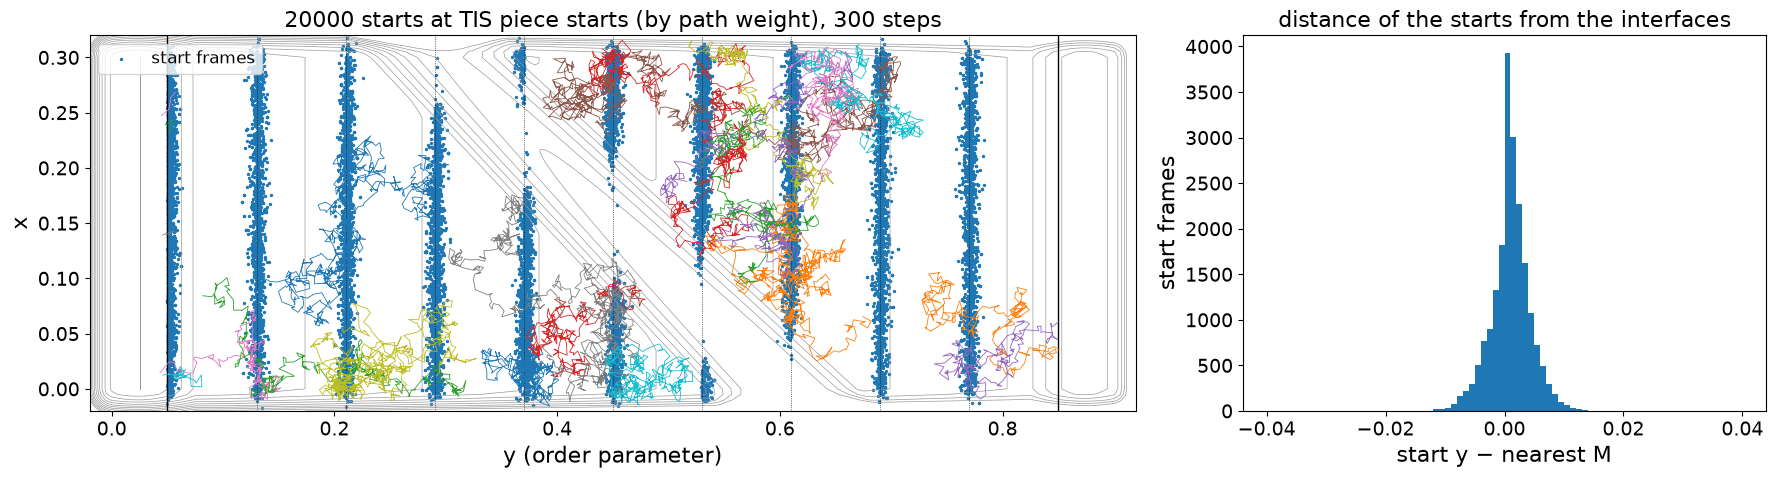

In [17]:
# Starts at the first frames of the TIS pieces, drawn with the path weights (distributed like the path data); fixed length.
TAG, TRAP = 'path_starts', 'fixed'
N_TRAJ, L, SEED = 20_000, 300, 0
PATH_NPZ = FIRST_TRY_NPZ    # TIS path data with i_traj and path_weights; with mirrored pieces (e.g. part 2's
                            # f'{FIG}/committor_staple_p1000.npz') half the starts lie before M, else all after

piece_start, y_ps, x_ps, w_ps = path_piece_starts(PATH_NPZ)
print(f'{len(piece_start):,} pieces outside A and B in {PATH_NPZ}')
rng = np.random.default_rng(SEED)
#pick = rng.choice(len(piece_start), N_TRAJ, p=w_ps / w_ps.sum())     # with replacement, by path weight
pick = rng.choice(len(piece_start), N_TRAJ)
start = piece_start[pick]                  # frame index in the path data
y0, x0 = y_ps[pick], x_ps[pick]
n_traj = N_TRAJ

y, x, i_traj, t_traj, first_frame = run_short(y0, x0, np.full(n_traj, L), SEED)
np.savez(f'{FIG}/short_traj_{TAG}_n{n_traj}_L{L}noweight.npz', y=y, x=x, i_traj=i_traj, t_traj=t_traj, start=start)
show_starts(y0, f'{n_traj} starts at TIS piece starts (by path weight), {L} steps')

20000 trajectories of 1 to 2839 steps (mean 298) in 1.2 s; 18% reached A or B
4,906,353 frames; 3081 in A, 510 in B
start offset from the nearest M: 31% before, 69% after, |offset| median 0.0020 (one step: 0.0045)


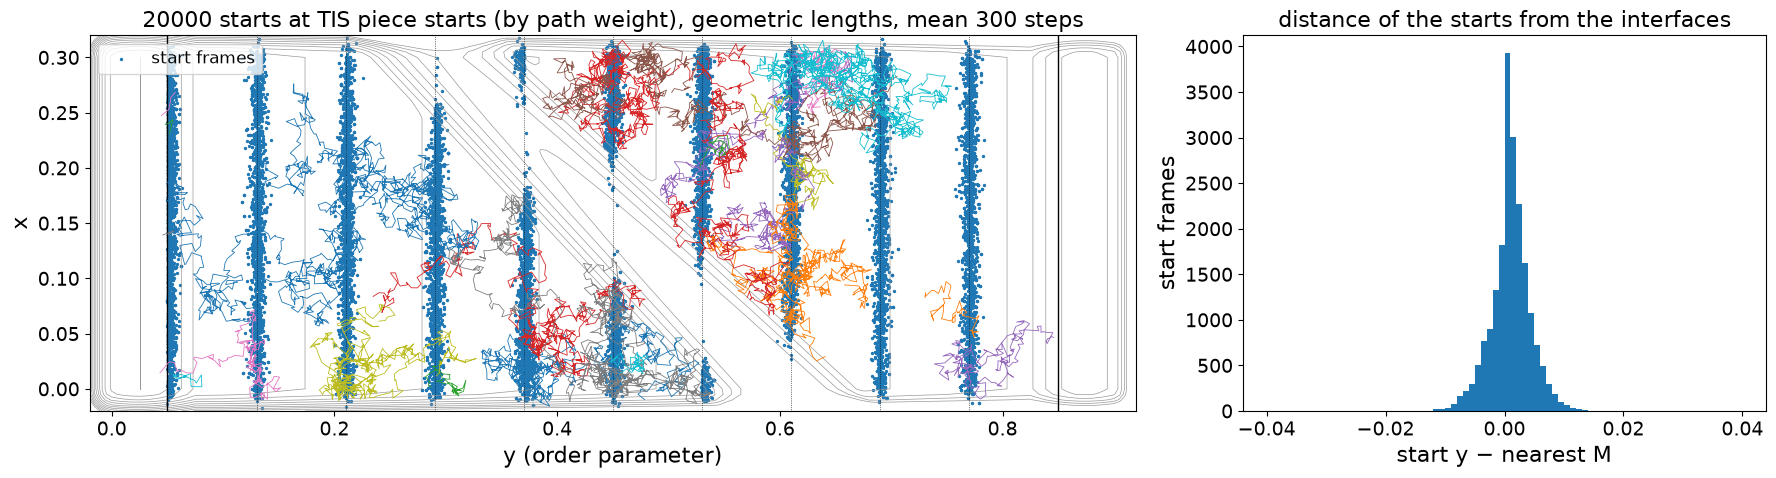

In [31]:
# As the previous cell, but with geometric lengths (mean L_MEAN), for the Poisson trap.
TAG, TRAP = 'path_starts_geom', 'poisson'
N_TRAJ, L_MEAN, SEED = 20_000, 300, 0
PATH_NPZ = FIRST_TRY_NPZ

def draw_lengths(n, rng):
    """Steps per trajectory. Geometric: every step is the last with probability 1 / L_MEAN, as
    set_poisson_traj_length_trap assumes. Another distribution here needs another trap."""
    return rng.geometric(1 / L_MEAN, n)

piece_start, y_ps, x_ps, w_ps = path_piece_starts(PATH_NPZ)
rng = np.random.default_rng(SEED)
#pick = rng.choice(len(piece_start), N_TRAJ, p=w_ps / w_ps.sum())
pick = rng.choice(len(piece_start), N_TRAJ)
start = piece_start[pick]
y0, x0 = y_ps[pick], x_ps[pick]
n_traj = N_TRAJ
lengths = draw_lengths(n_traj, rng)
L = int(lengths.max())                     # longest trajectory (file names)

y, x, i_traj, t_traj, first_frame = run_short(y0, x0, lengths, SEED)
np.savez(f'{FIG}/short_traj_{TAG}_n{n_traj}_Lmean{L_MEAN}noweight.npz', y=y, x=x, i_traj=i_traj, t_traj=t_traj, start=start, lengths=lengths)
show_starts(y0, f'{n_traj} starts at TIS piece starts (by path weight), geometric lengths, mean {L_MEAN} steps')

20000 trajectories in 5 s, 9,658,592 frames; ended by: L_MAX 0.0%, A 21.0%, B 5.2%, turn 73.8%; 0 steps crossed more than one interface
steps per trajectory: median 330.0 | 99% 2265.029999999995 | max 5997
turns around interface: {np.float64(0.13): np.int64(428), np.float64(0.21): np.int64(1613), np.float64(0.29): np.int64(1755), np.float64(0.37): np.int64(2340), np.float64(0.45): np.int64(2241), np.float64(0.53): np.int64(1844), np.float64(0.61): np.int64(1655), np.float64(0.69): np.int64(1694), np.float64(0.77): np.int64(1191)}
start offset from the nearest M: 31% before, 69% after, |offset| median 0.0020 (one step: 0.0045)


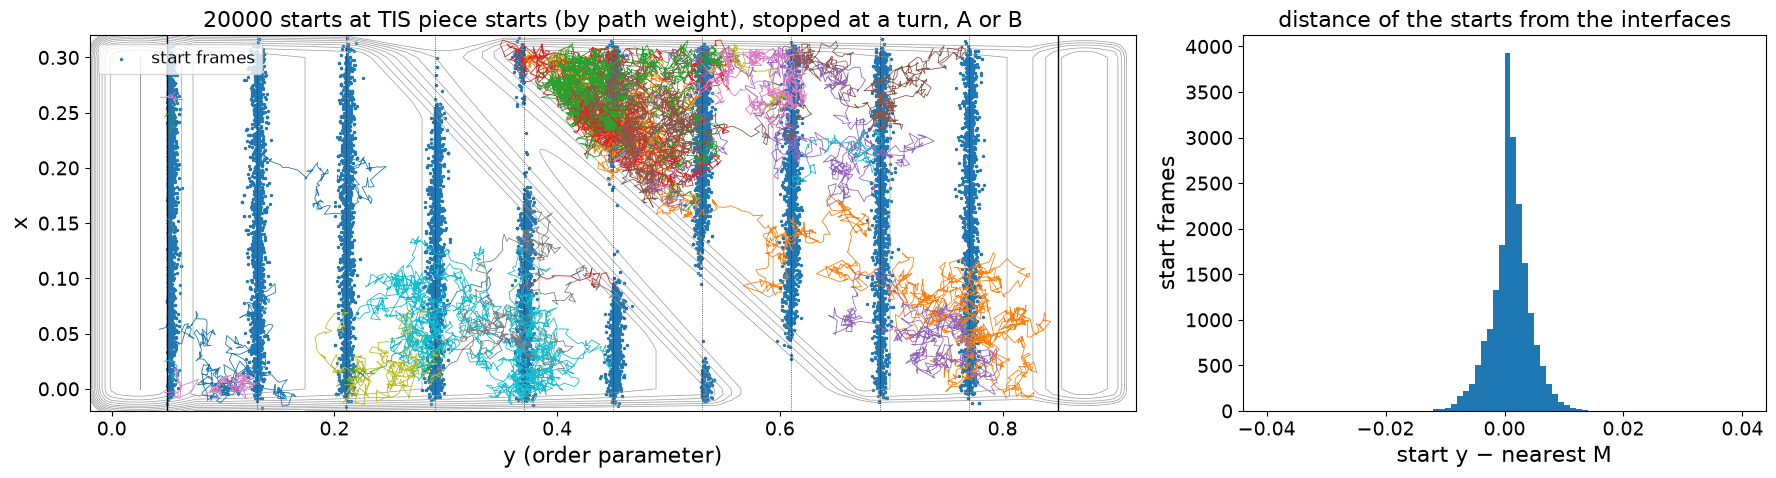

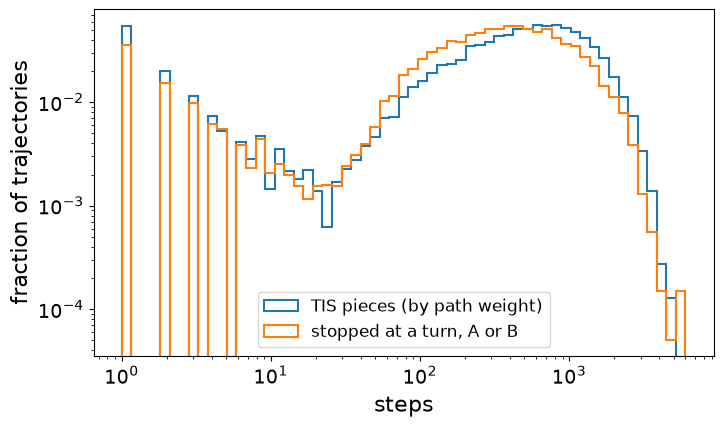

In [14]:
# Starts at the TIS piece starts (by path weight); every trajectory runs until it makes a turn (toytis' [i*] rule),
# reaches A or B, or reaches L_MAX steps.
TAG, TRAP = 'path_starts_turn', 'absorb'
N_TRAJ, L_MAX, SEED = 20_000, 20_000, 0
PATH_NPZ = FIRST_TRY_NPZ

piece_start, y_ps, x_ps, w_ps = path_piece_starts(PATH_NPZ)
rng = np.random.default_rng(SEED)
#pick = rng.choice(len(piece_start), N_TRAJ, p=w_ps / w_ps.sum())
pick = rng.choice(len(piece_start), N_TRAJ)
start = piece_start[pick]
y0, x0 = y_ps[pick], x_ps[pick]
n_traj, L = N_TRAJ, L_MAX

intf = cp.asarray(INTERFACES, dtype=cp.float64)
sigma = np.sqrt(2 * kT * dt / gamma_md)
cp.random.seed(SEED)
# state of the running walkers only (compacted every step)
id_a = cp.arange(n_traj)
y_a, x_a = cp.asarray(y0, dtype=cp.float64), cp.asarray(x0, dtype=cp.float64)
cell_a = cp.searchsorted(intf, y_a)                                   # interval between interfaces
last_a = cp.abs(y_a[:, None] - intf[None, :]).argmin(1)              # just crossed: the nearest M
# as toytis: the start has just crossed M, coming from the interface on its other side
prev_a = cp.where(y_a > intf[last_a], last_a - 1, last_a + 1)          # the distinct interface crossed before it
prev_a = cp.where((prev_a < 0) | (prev_a >= len(INTERFACES)), -1, prev_a)
frames = [(y_a, x_a, id_a, cp.zeros(n_traj, cp.int32))]
end = cp.zeros(n_traj, cp.int8)                                       # 0: L_MAX, 1: A, 2: B, 3: turn
turn_intf = cp.full(n_traj, -1)
n_jumps = cp.zeros((), cp.int64)
t0 = time.time()
for step in range(1, L_MAX + 1):
    fy, fx = force(y_a, x_a)
    y_a = y_a + dt / gamma_md * fy + sigma * cp.random.standard_normal(y_a.size)
    x_a = x_a + dt / gamma_md * fx + sigma * cp.random.standard_normal(x_a.size)
    cell_new = cp.searchsorted(intf, y_a)
    crossed = cell_new != cell_a
    n_jumps += cp.sum(cp.abs(cell_new - cell_a) > 1)                  # more than one interface in one step
    j = cp.where(cell_new > cell_a, cell_new - 1, cell_new)          # the (last) interface crossed this step
    new = crossed & (j != last_a)
    turn = new & (j == prev_a)                                        # back past the one before: turn around last_a
    turned_around = last_a
    prev_a = cp.where(new, last_a, prev_a)
    last_a = cp.where(new, j, last_a)
    cell_a = cell_new
    frames.append((y_a, x_a, id_a, cp.full(y_a.size, step, cp.int32)))
    in_A, in_B = y_a <= lambda_A, y_a >= lambda_B
    stop = in_A | in_B | turn
    end[id_a[stop]] = cp.where(in_A, 1, cp.where(in_B, 2, 3)).astype(cp.int8)[stop]
    turn_intf[id_a[turn & ~in_A & ~in_B]] = turned_around[turn & ~in_A & ~in_B]
    go = ~stop
    id_a, y_a, x_a, cell_a, last_a, prev_a = (a[go] for a in (id_a, y_a, x_a, cell_a, last_a, prev_a))
    if id_a.size == 0:
        break

# frames in trajectory order
Yf, Xf, If, Tf = (cp.concatenate([f[k] for f in frames]) for k in range(4))
del frames
order = cp.lexsort(cp.stack([Tf, If]))
y, x, i_traj, t_traj = (a[order].get() for a in (Yf, Xf, If, Tf))
del Yf, Xf, If, Tf, order
t_traj = t_traj.astype(float)
end, turn_intf = end.get(), turn_intf.get()
lengths = np.bincount(i_traj, minlength=n_traj) - 1                  # steps per trajectory
first_frame = np.r_[0, np.cumsum(lengths + 1)[:-1]]
stop_end = np.zeros(len(y), bool)                                    # last frames of the trajectories stopped by a turn
stop_end[(first_frame + lengths)[end == 3]] = True
print(f'{n_traj} trajectories in {time.time() - t0:.0f} s, {len(y):,} frames; ended by: '
      + ', '.join(f'{name} {np.mean(end == k):.1%}' for k, name in enumerate(('L_MAX', 'A', 'B', 'turn')))
      + f'; {int(n_jumps)} steps crossed more than one interface')
print('steps per trajectory: median', np.median(lengths), '| 99%', np.percentile(lengths, 99), '| max', lengths.max())
print('turns around interface:', dict(zip(*np.unique(np.array(INTERFACES)[turn_intf[end == 3]], return_counts=True))))
np.savez(f'{FIG}/short_traj_{TAG}_n{n_traj}_Lmax{L_MAX}noweight.npz', y=y, x=x, i_traj=i_traj, t_traj=t_traj, start=start,
         end=end, turn_intf=turn_intf)
show_starts(y0, f'{n_traj} starts at TIS piece starts (by path weight), stopped at a turn, A or B')

# lengths against the TIS pieces of PATH_NPZ (piece weight: its path weight)
dp = d if PATH_NPZ == FIRST_TRY_NPZ else np.load(PATH_NPZ)
i_p = dp['i_traj']
s_p = np.flatnonzero(np.r_[True, i_p[1:] != i_p[:-1]])
len_p = np.diff(np.r_[s_p, len(i_p)]) - 1
w_p = dp['path_weights'][s_p].astype(float)
bins = np.logspace(0, np.log10(max(lengths.max(), len_p.max()) + 1), 60)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(len_p, bins=bins, weights=w_p / w_p.sum(), histtype='step', lw=1.5, label='TIS pieces (by path weight)')
ax.hist(lengths, bins=bins, weights=np.full(n_traj, 1 / n_traj), histtype='step', lw=1.5, label='stopped at a turn, A or B')
ax.set(xscale='log', yscale='log', xlabel='steps', ylabel='fraction of trajectories')
ax.legend()
fig.savefig(f'{FIG}/lengths_{TAG}noweight.png', dpi=100, bbox_inches='tight')
plt.show()

### NPNEq fit on the short trajectories

`CommittorNE` with one segment per trajectory. The trajectories that reach A or B are treated as staying there (`set_fixed_traj_length_trap`; this only affects the Z_q plots, not the fit). CVs: y and x, one drawn at random every iteration. A warm-up with a very wide envelope, then the usual envelope 0.01.

#=500, dr2=120.062, sdzq=3.94904, |dx|=0.358218, time=33.7817
#=1000, dr2=118.797, sdzq=3.89772, |dx|=0.00101396, time=67.6097


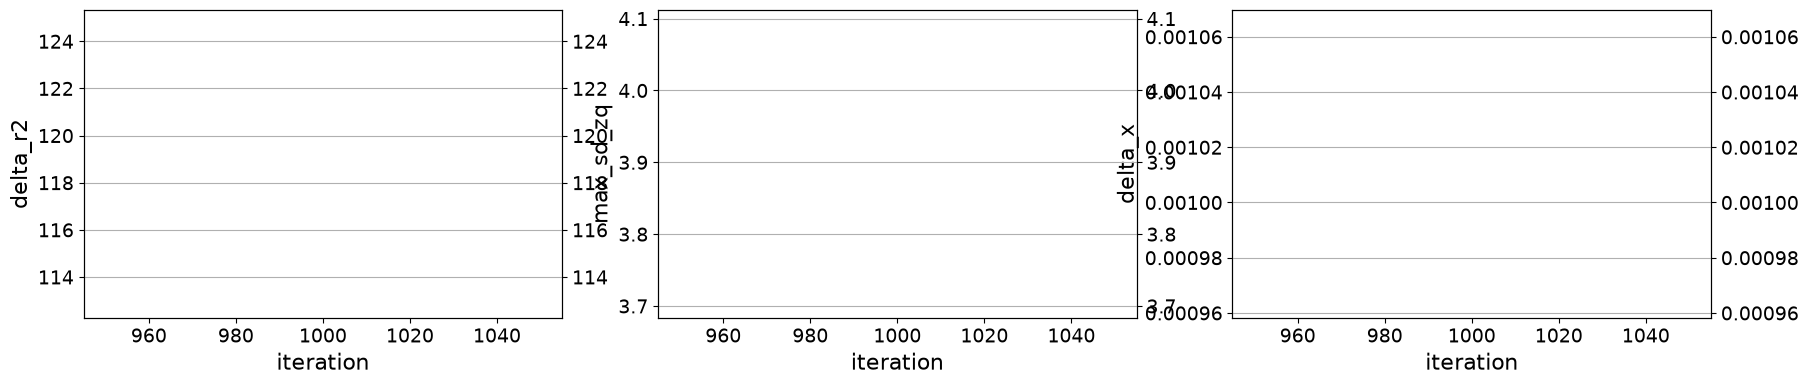

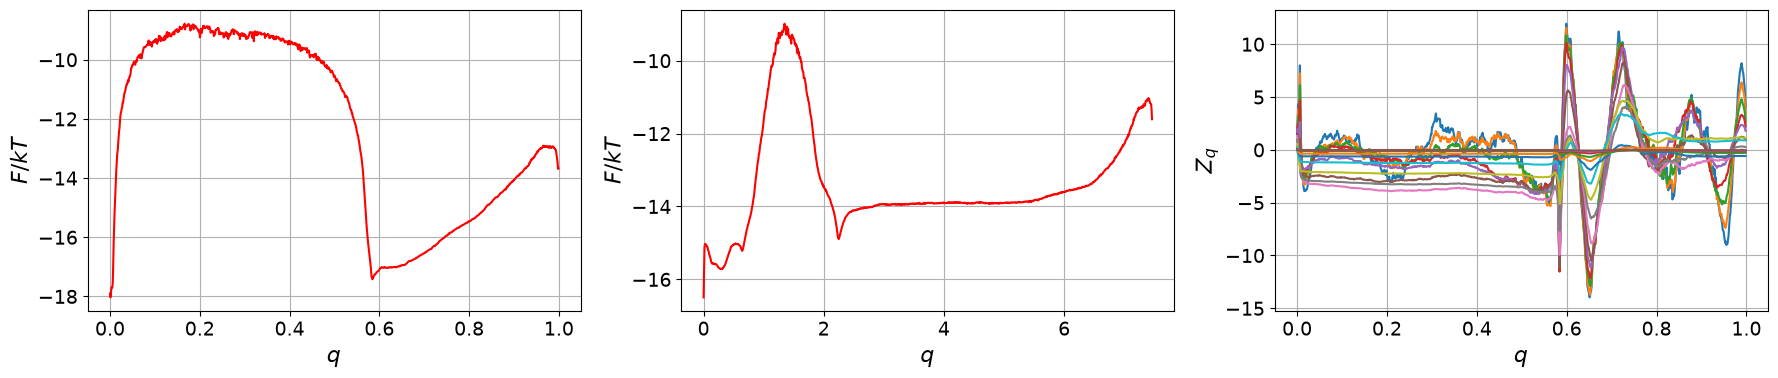

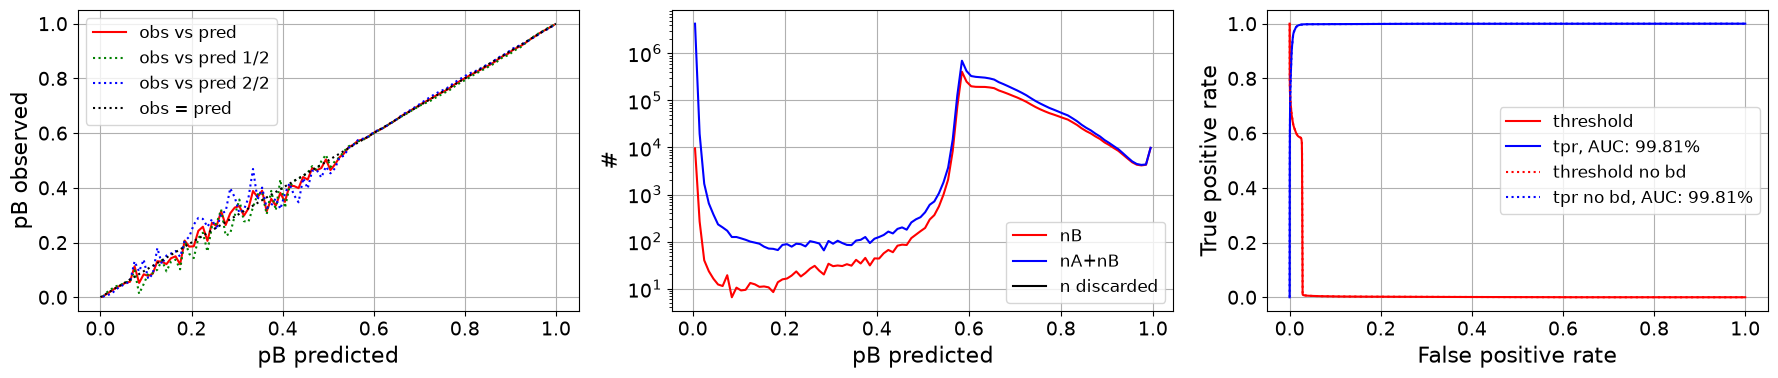

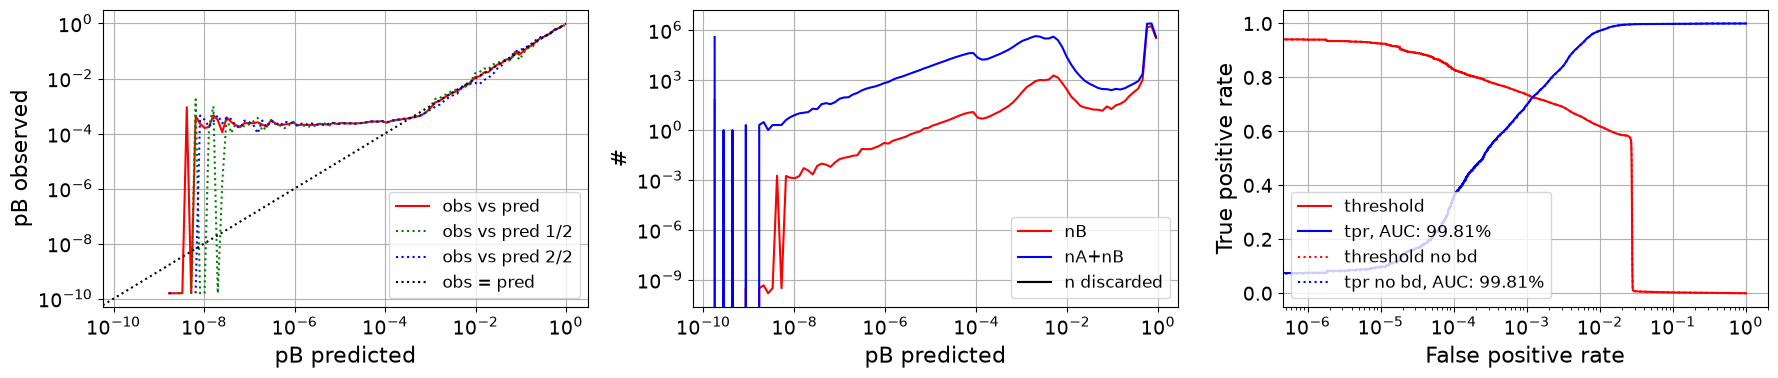

#=2000, dr2=111.287, sdzq=1.30749, |dx|=0.00833537, time=66.9892
#=3000, dr2=111.234, sdzq=1.33432, |dx|=0.00021126, time=134.045
#=4000, dr2=111.261, sdzq=1.36638, |dx|=0.000213302, time=201.092
#=5000, dr2=111.335, sdzq=1.31881, |dx|=0.000204599, time=268.137
#=6000, dr2=111.247, sdzq=1.30436, |dx|=0.000191937, time=335.191


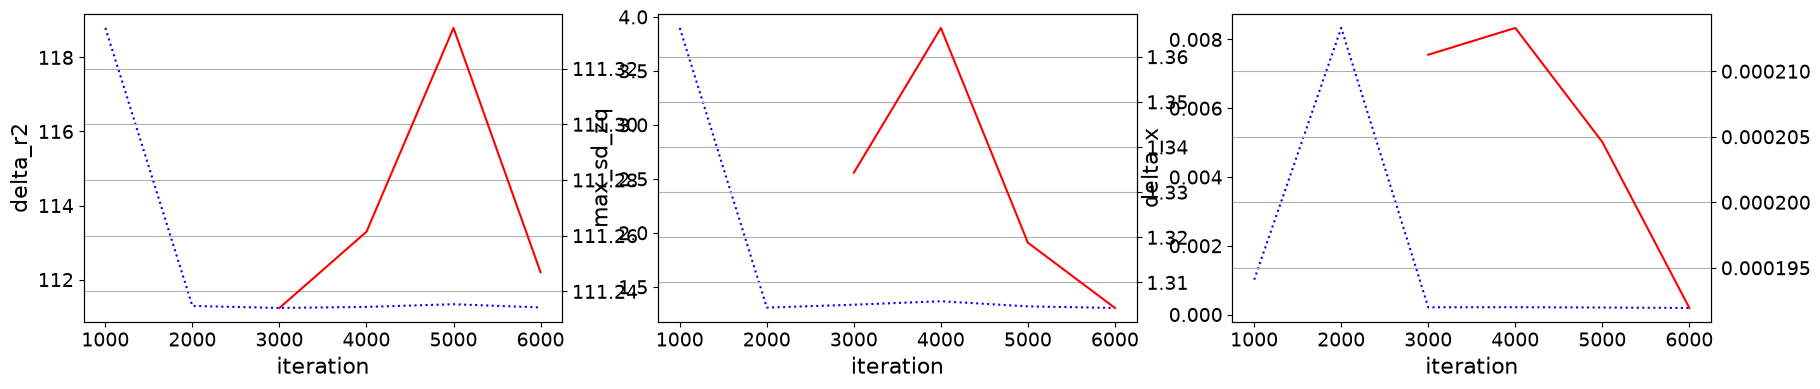

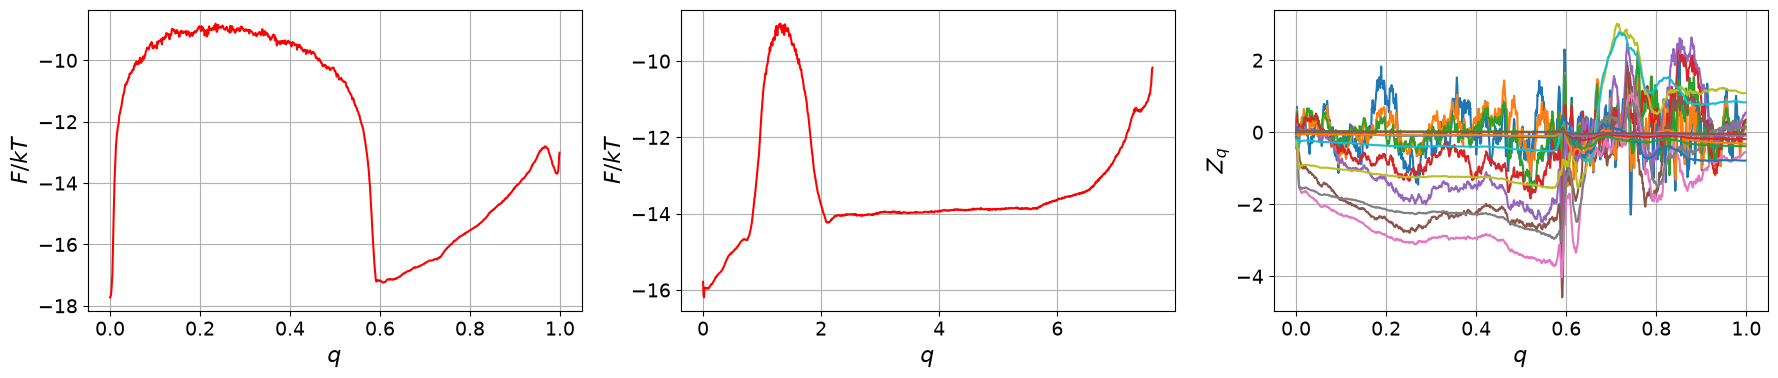

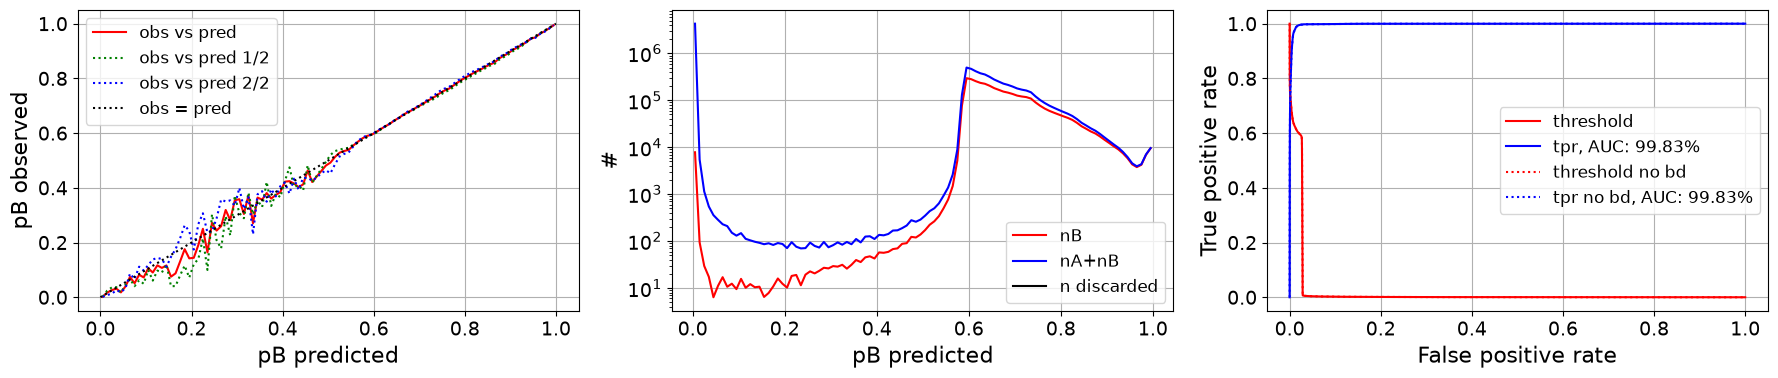

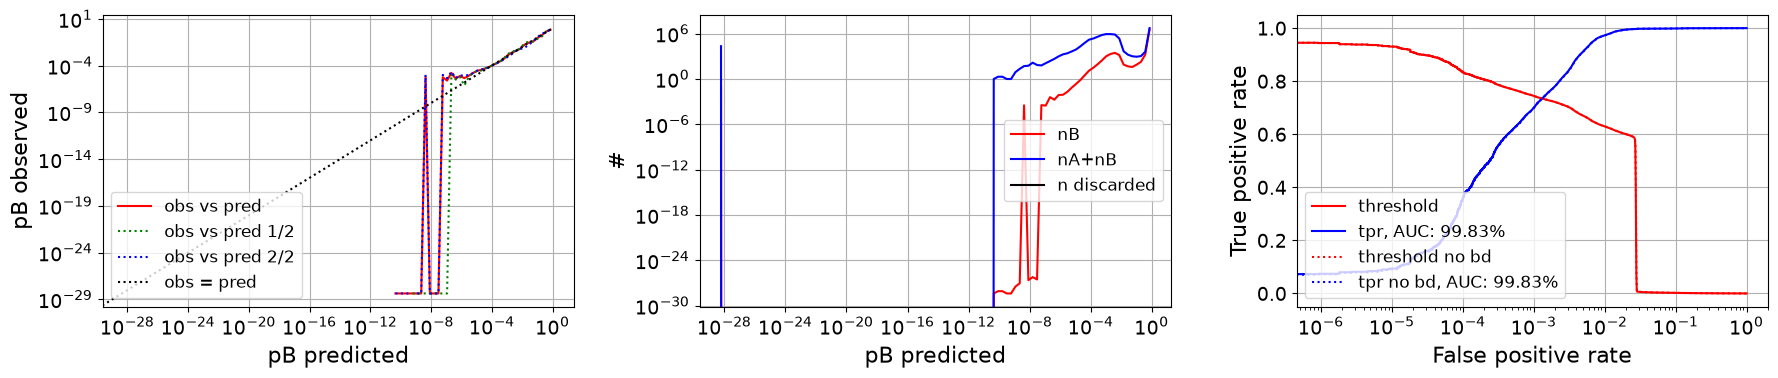

#=7000, dr2=111.338, sdzq=1.26299, |dx|=0.000186089, time=66.9272
#=8000, dr2=111.351, sdzq=1.27019, |dx|=3.45665e-05, time=133.987
#=9000, dr2=111.363, sdzq=1.27352, |dx|=5.44667e-05, time=201.054
#=10000, dr2=111.383, sdzq=1.27903, |dx|=4.52456e-05, time=268.108
#=11000, dr2=111.397, sdzq=1.28876, |dx|=4.29812e-05, time=335.163


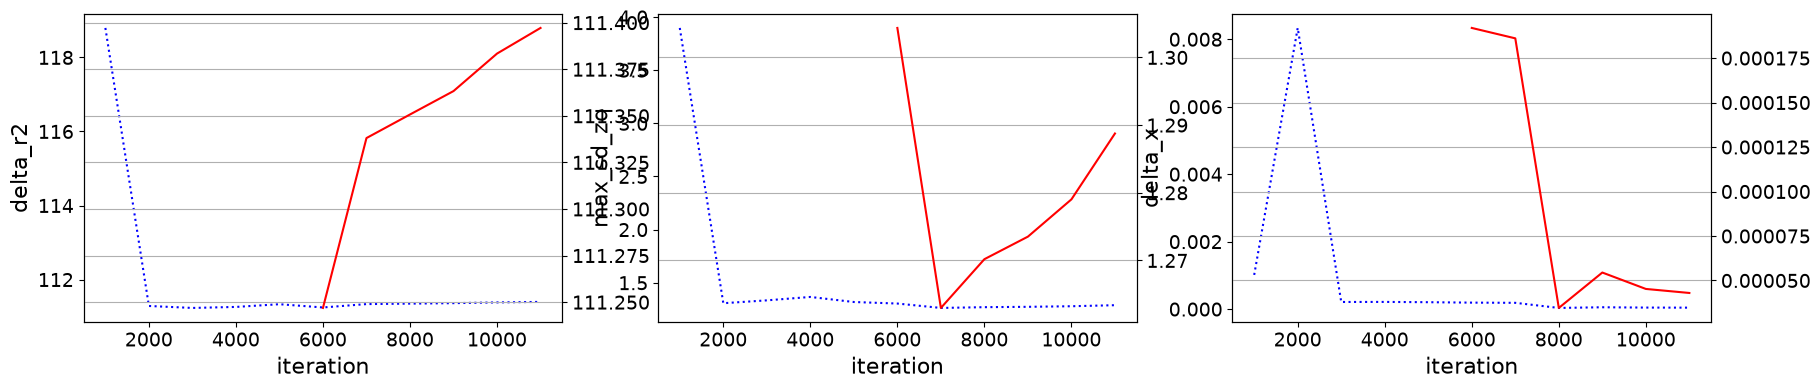

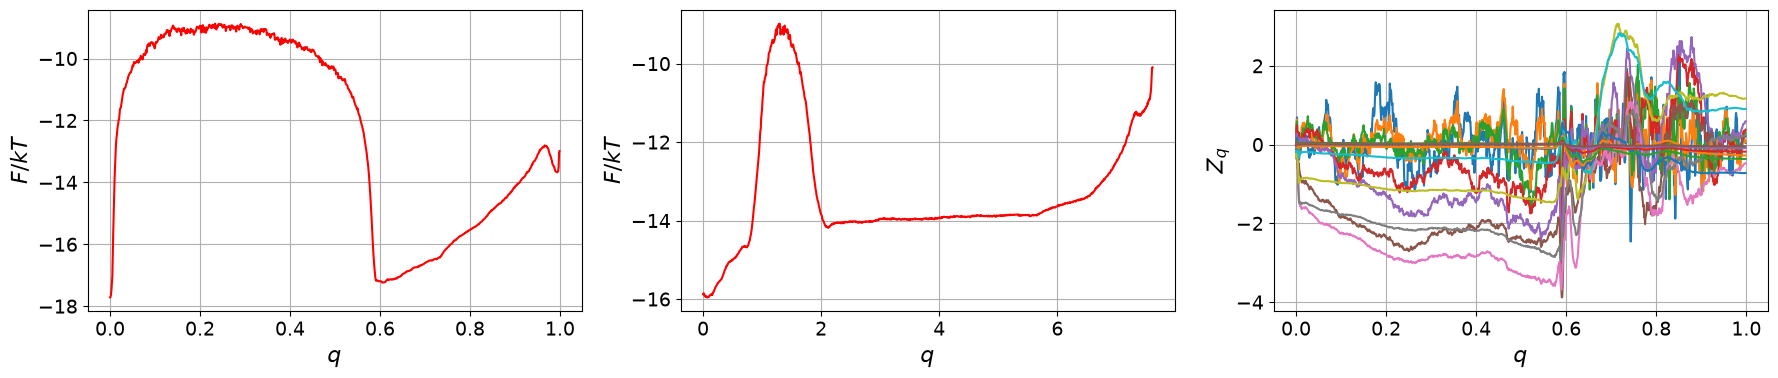

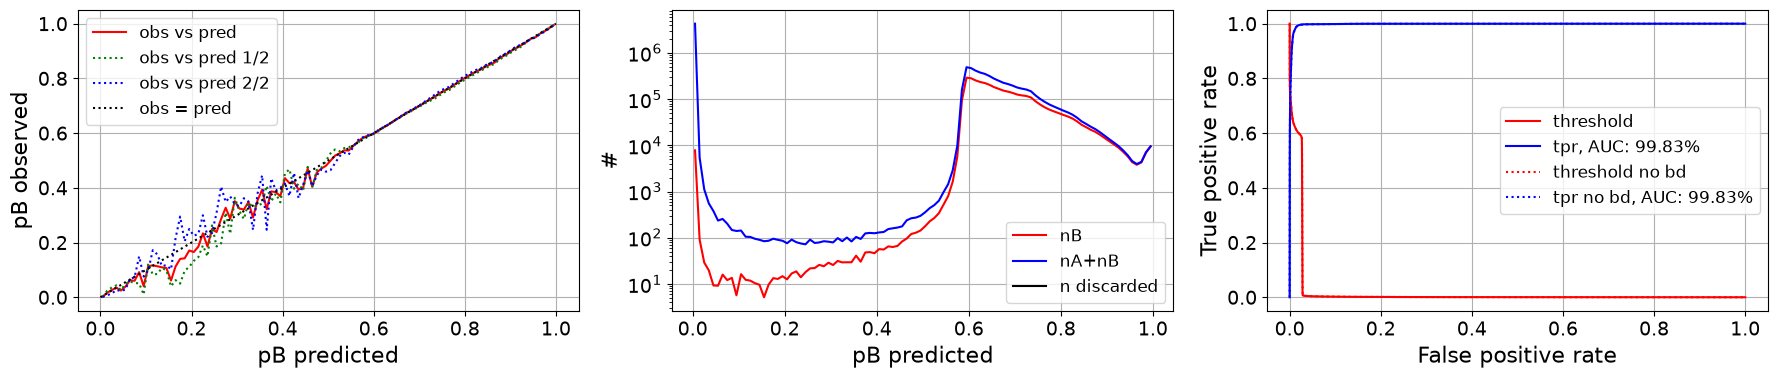

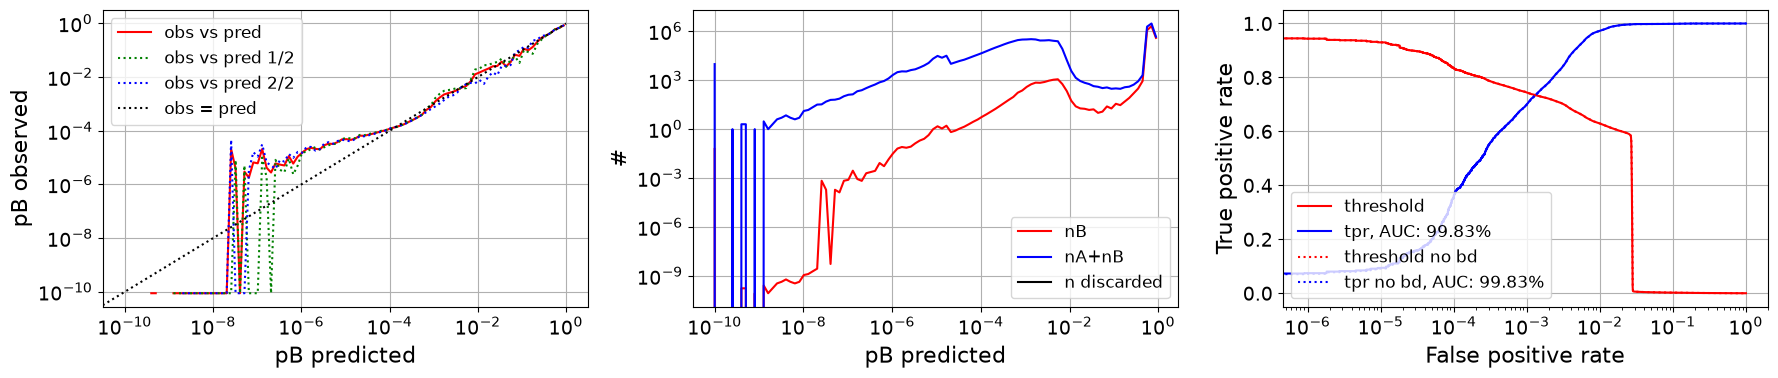

#=12000, dr2=111.374, sdzq=1.29244, |dx|=6.55345e-05, time=66.8617
#=13000, dr2=111.417, sdzq=1.32081, |dx|=6.24969e-05, time=133.92

Training interrupted at iteration 13918; keeping the RC of the last completed update.


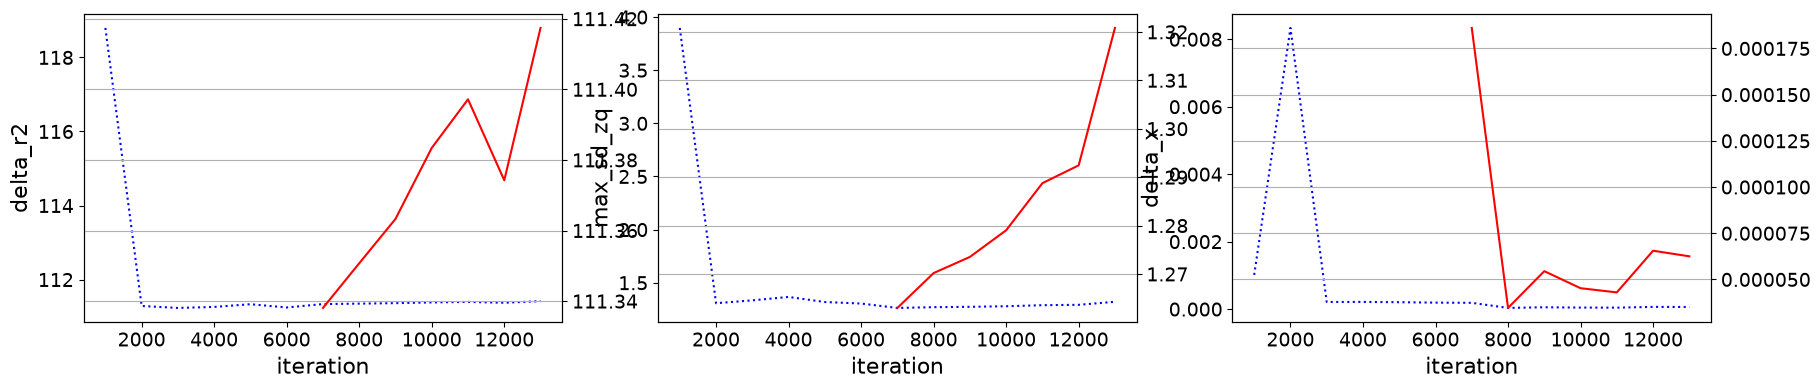

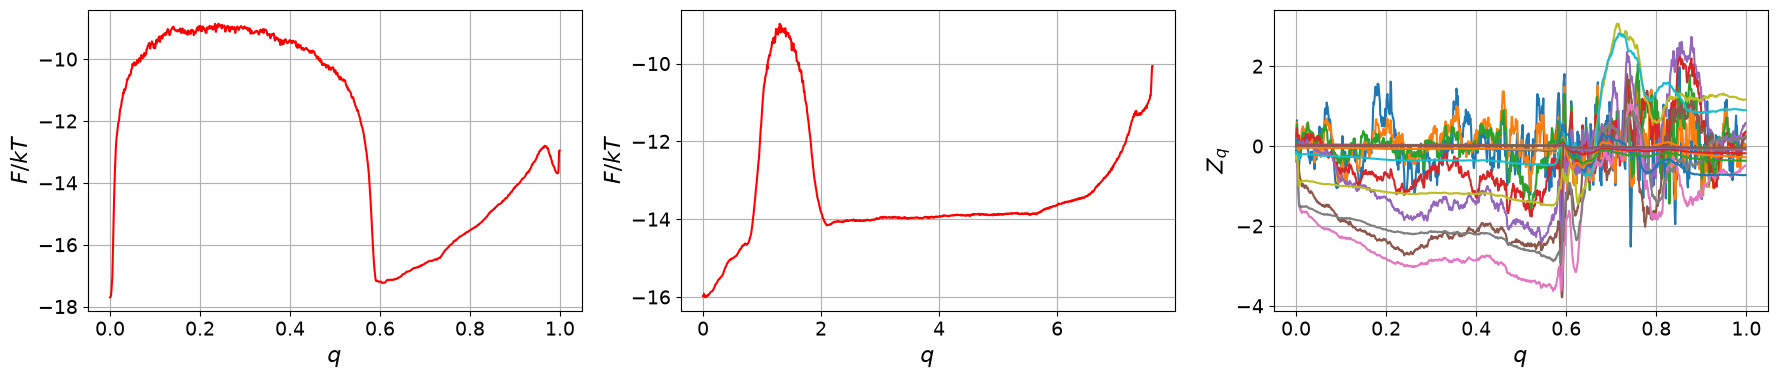

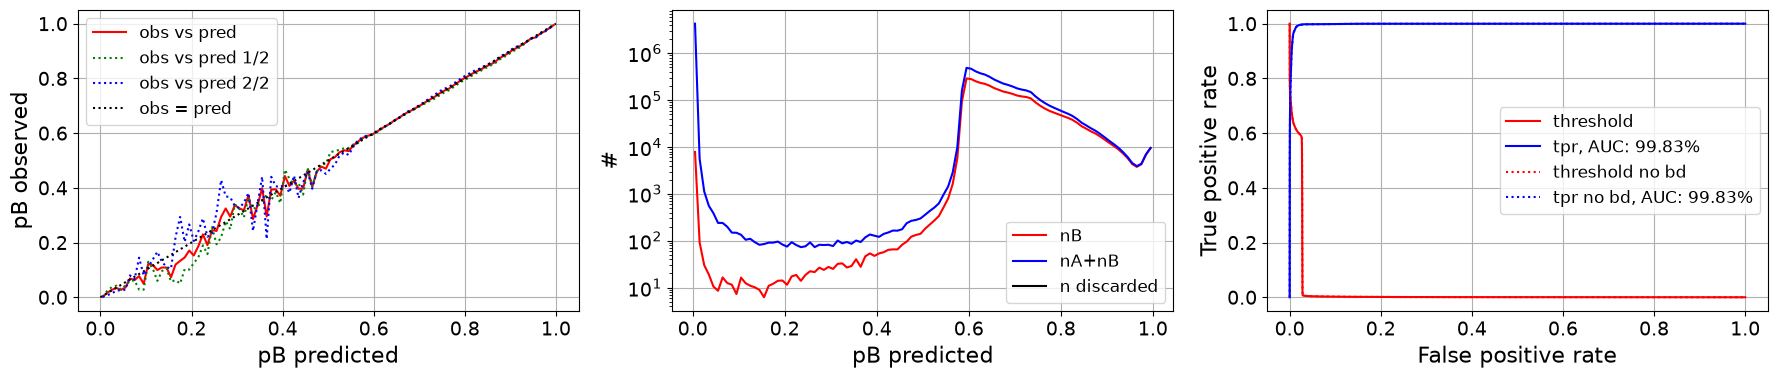

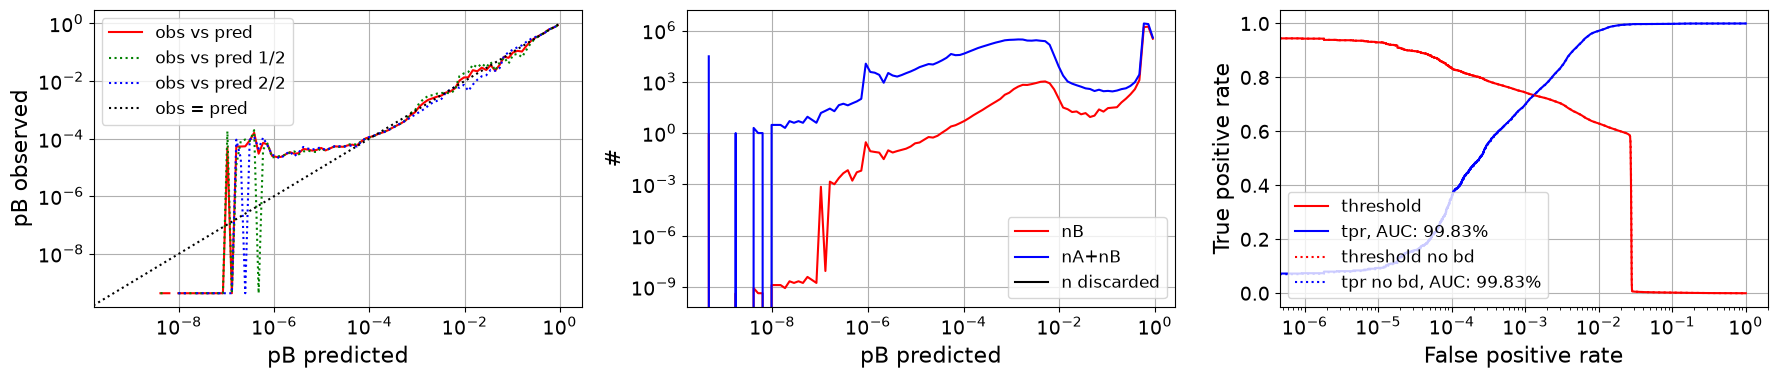

In [15]:
boundary0, boundary1 = y <= lambda_A, y >= lambda_B

q = optimalrcs.CommittorNE(boundary0=boundary0, boundary1=boundary1, i_traj=i_traj, t_traj=t_traj)
if TRAP == 'poisson':      # geometric lengths: absorbed trajectories continue for an exponential number of frames
    q.set_poisson_traj_length_trap(boundary0 | boundary1, L_MEAN)
elif TRAP == 'absorb':    # stopped at a turn: absorbed trajectories stay in A or B
    q.set_fixed_traj_length_trap(boundary0 | boundary1, 2 ** 16)
   # q.set_fixed_traj_length_trap(boundary0 | boundary1, 400)
    if not hasattr(q, 'set_stopped_traj_end'):
        raise RuntimeError('set_stopped_traj_end is in the optimalrcs-cupy of the repo, not in ORIG_LIB: import that one')
    q.set_stopped_traj_end(stop_end)     # turn-stopped trajectories: Z_q uses q at the stop for windows that pass it
else:                     # fixed length: absorbed trajectories continue to L + 1 frames
    q.set_fixed_traj_length_trap(boundary0 | boundary1, L + 1)

cvs = [cp.asarray(y), cp.asarray(x)]
def comp_y():
    return cvs[np.random.randint(len(cvs))]

metrics_print = ('iter', 'delta_r2', 'max_sd_zq', 'delta_x', 'time_elapsed')
np.random.seed(0)
cp.random.seed(0)

optimalrcs.envelope_scale = 1e6          # warm-up
q.fit_transform(comp_y, gamma=0, ny=6, max_iter=1000, print_step=500, metrics_print=metrics_print,
                delta_r2_max_change_allowed=10000)
show(lambda: q.plots_metrics(['delta_r2', 'max_sd_zq', 'delta_x']), 'fit_metrics')
show(lambda: q.plots_feps(delta_t_sim=dt), 'fit_feps')
show(lambda: q.plots_obs_pred(), 'fit_obs_pred')
show(lambda: q.plots_obs_pred(log_scale=True), 'fit_obs_pred_log')
optimalrcs.envelope_scale = 0.01         # main fit
for _ in range(3):
    q.fit_transform(comp_y, gamma=0, ny=6, max_iter=5000, print_step=1000, metrics_print=metrics_print)
    show(lambda: q.plots_metrics(['delta_r2', 'max_sd_zq', 'delta_x']), 'fit_metrics')
    show(lambda: q.plots_feps(delta_t_sim=dt), 'fit_feps')
    show(lambda: q.plots_obs_pred(), 'fit_obs_pred')
    show(lambda: q.plots_obs_pred(log_scale=True), 'fit_obs_pred_log')

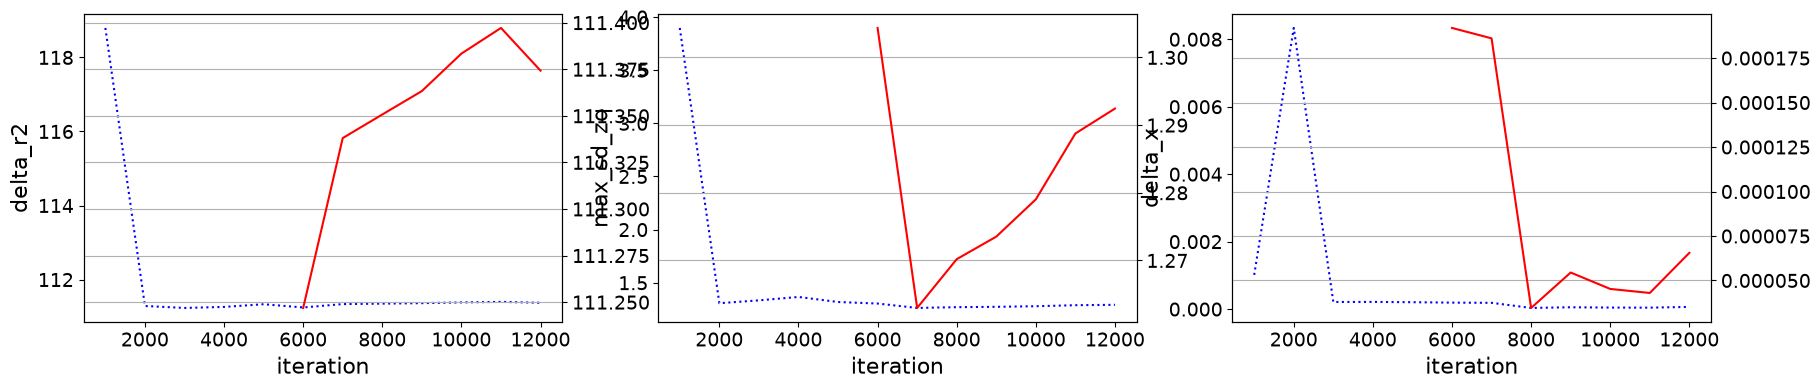

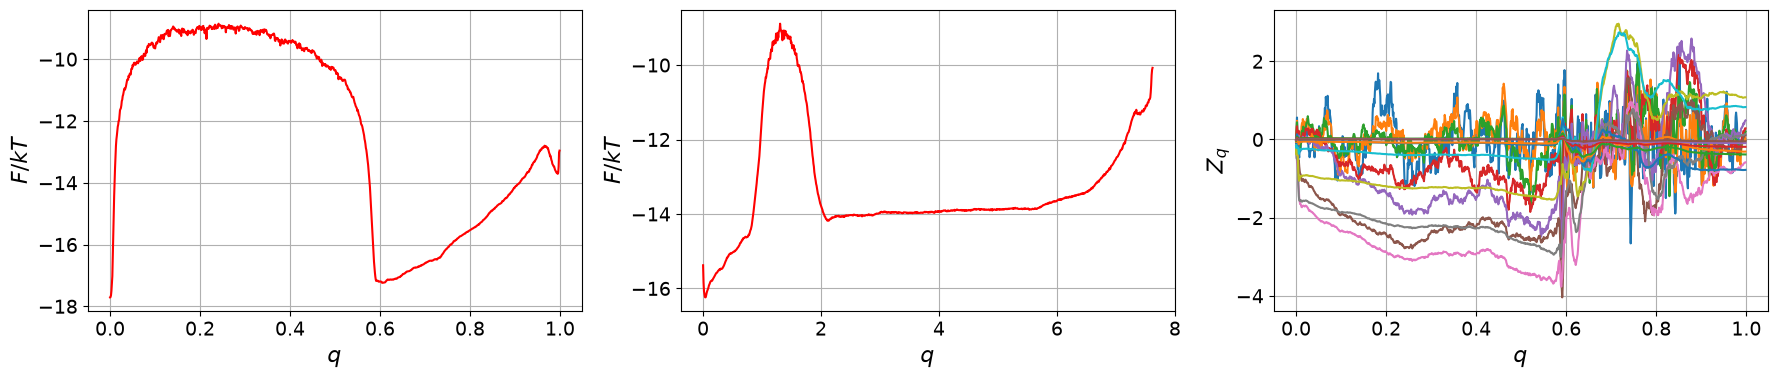

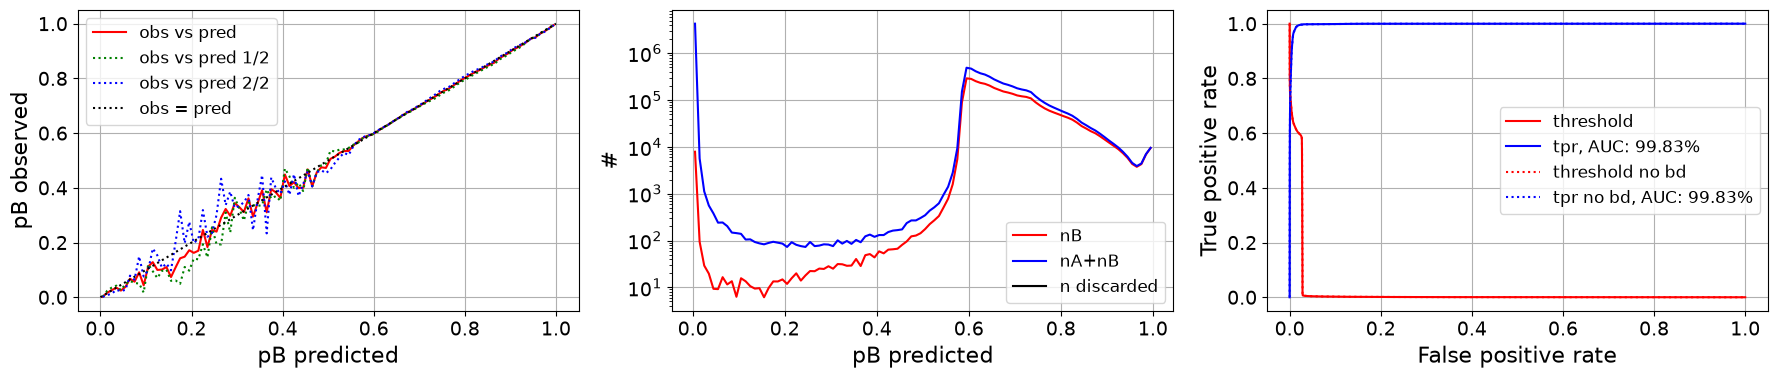

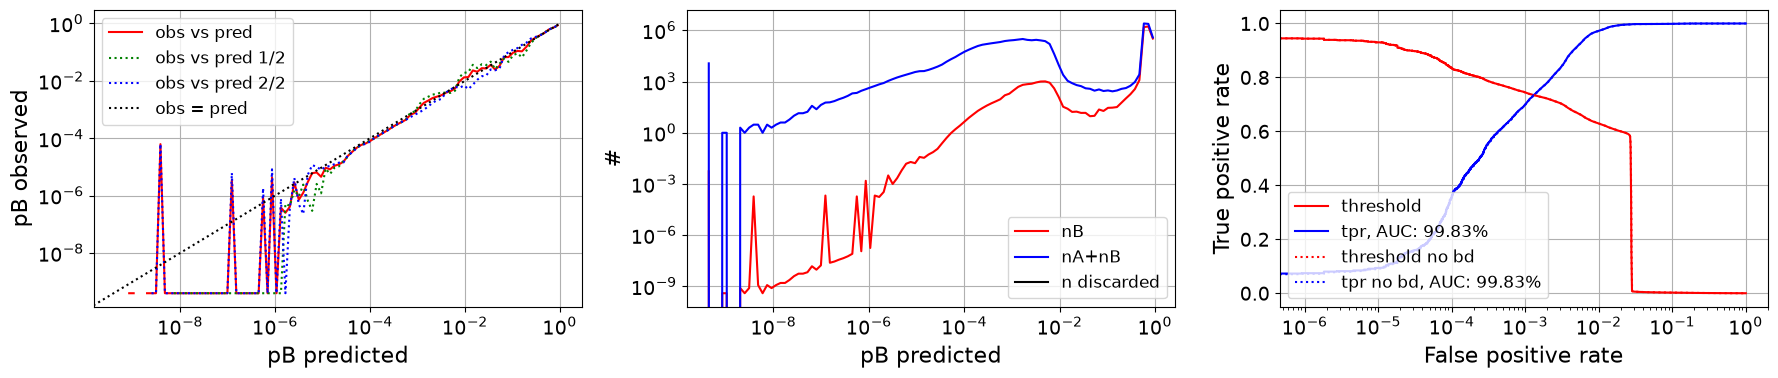

In [11]:
show(lambda: q.plots_metrics(['delta_r2', 'max_sd_zq', 'delta_x']), f'fit_metrics_{TAG}stopped')
show(lambda: q.plots_feps(delta_t_sim=dt), f'fit_feps_{TAG}stopped')
show(lambda: q.plots_obs_pred(), f'fit_obs_pred_{TAG}stopped')
show(lambda: q.plots_obs_pred(log_scale=True), f'fit_obs_pred_log_{TAG}stopped')

### Comparison with the exact committor and the first try

The exact committor of this dynamics (finite-volume solution of the backward equation, `figures_by_potential/2d_zpot/brownian_g10/reference_and_analyses/committor_reference.py`; checked by shooting to absorption at 200 path frames, see the notes §13.1), if the file is there. Engine shooting at four points on the plateau beyond the ridge. The new fit at the start frames (each is a frame of the first-try data too) against the first try.

RMS(fit - exact) per (y, x) bin, 0.05 < q_exact < 0.95: 0.0232
point (y, x)    shooting   new fit   first try
(0.50, 0.25)     0.639     0.613     0.707
(0.55, 0.10)     0.664     0.645     0.738
(0.62, 0.15)     0.698     0.669     0.754
(0.70, 0.15)     0.747     0.726     0.799
at the 20000 start frames: new fit - first try: mean -0.0352, RMS 0.0532
at the 20000 start frames: new fit - exact: mean -0.0099, RMS 0.0149


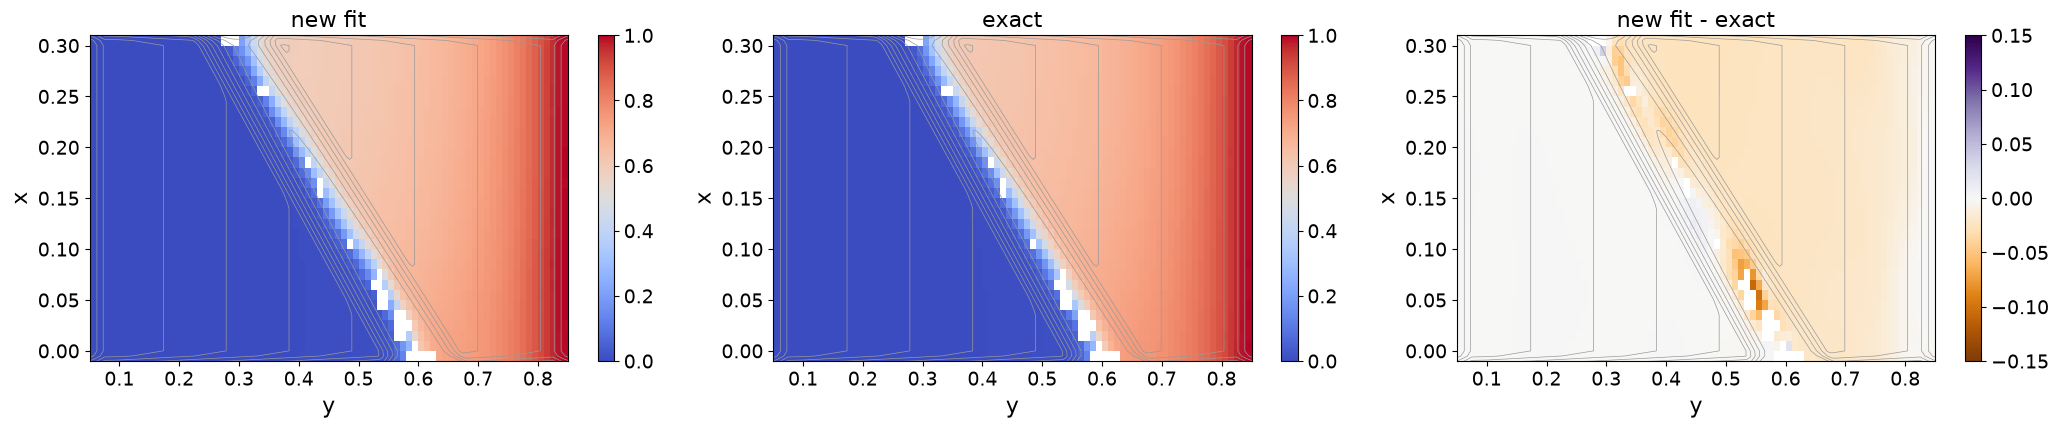

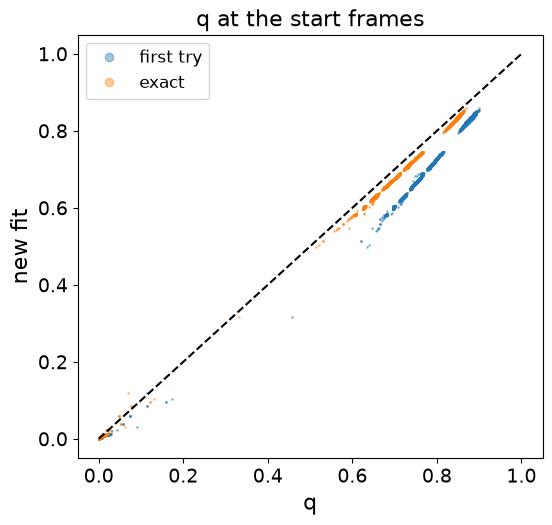

In [16]:
from scipy.interpolate import RegularGridInterpolator
REFERENCE_NPZ = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/brownian_g10/reference_and_analyses/committor_reference_h0.001.npz'

r = q.r_traj.get()
free = ~(boundary0 | boundary1)
ey, ex = np.linspace(lambda_A, lambda_B, 81), np.linspace(-0.01, 0.31, 33)
counts = np.histogram2d(y[free], x[free], bins=(ey, ex))[0]
def bin_mean(values):
    s = np.histogram2d(y[free], x[free], bins=(ey, ex), weights=values[free])[0]
    return np.where(counts >= 20, s / np.maximum(counts, 1), np.nan)
Q_fit = bin_mean(r)

q_exact = None
if os.path.exists(REFERENCE_NPZ):
    ref = np.load(REFERENCE_NPZ)
    f_ref = RegularGridInterpolator((ref['y'], ref['x']), ref['q'], bounds_error=False, fill_value=None)
    q_exact = np.clip(f_ref(np.column_stack([y, x])), 0, 1)
    Q_exact = bin_mean(q_exact)
    transition = (Q_exact > 0.05) & (Q_exact < 0.95)
    print(f'RMS(fit - exact) per (y, x) bin, 0.05 < q_exact < 0.95: {np.sqrt(np.nanmean((Q_fit - Q_exact)[transition] ** 2)):.4f}')
else:
    print('no reference file: no exact committor')

# engine shooting at four plateau points (1200 trajectories each, run until A or B)
shooting = [((0.50, 0.25), 0.639), ((0.55, 0.10), 0.664), ((0.62, 0.15), 0.698), ((0.70, 0.15), 0.747)]
print('point (y, x)    shooting   new fit   first try')
for (py, px), q_shoot in shooting:
    near = free & ((y - py) ** 2 + (x - px) ** 2 < 0.01 ** 2)
    near_first = free_first & ((y_first - py) ** 2 + (x_first - px) ** 2 < 0.01 ** 2)
    print(f'({py:.2f}, {px:.2f})     {q_shoot:.3f}     {r[near].mean():.3f}     {q_first[near_first].mean():.3f}')

at_start = {'new fit': r[first_frame], 'first try': q_first[start]}
if q_exact is not None:
   at_start['exact'] = q_exact[first_frame]
for name in [n for n in at_start if n != 'new fit']:
    diff = at_start['new fit'] - at_start[name]
    print(f'at the {n_traj} start frames: new fit - {name}: mean {diff.mean():+.4f}, RMS {np.sqrt(np.mean(diff ** 2)):.4f}')

panels = [(Q_fit, 'new fit', 'coolwarm', 0, 1)]
if q_exact is not None:
    panels += [(Q_exact, 'exact', 'coolwarm', 0, 1), (Q_fit - Q_exact, 'new fit - exact', 'PuOr', -0.15, 0.15)]
fig, axes = plt.subplots(1, len(panels), figsize=(7 * len(panels), 4.5), squeeze=False)
for ax, (M, title, cmap, vmin, vmax) in zip(axes[0], panels):
    im = ax.pcolormesh(ey, ex, M.T, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.contour(gy, gx, ((V - V.min()) / kT).T, levels=V_levels, colors='0.6', linewidths=0.5)
    ax.set(title=title, xlabel='y', ylabel='x', xlim=(lambda_A, lambda_B), ylim=(-0.01, 0.31))
    fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(f'{FIG}/maps_{TAG}stopped.png', dpi=100, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot(at_start['first try'], at_start['new fit'], '.', ms=2, alpha=0.4, label='first try')
if q_exact is not None:
    ax.plot(at_start['exact'], at_start['new fit'], '.', ms=2, alpha=0.4, label='exact')
ax.plot([0, 1], [0, 1], 'k--')
ax.set(xlabel='q', ylabel='new fit', title='q at the start frames')
ax.legend(markerscale=6)
fig.savefig(f'{FIG}/at_start_frames_{TAG}stopped.png', dpi=100, bbox_inches='tight')
plt.show()

### Save

In the format the first-try cell reads (`X_all`, `r`, `i_traj`, `t_traj`), so the next round can start from this fit (set `FIRST_TRY_NPZ` to it).

In [13]:
OUT_NPZ = f'{FIG}/committor_short_traj_{BIN_ON}_n{n_traj}_L{L}_{TAG}stopped.npz'
np.savez(OUT_NPZ, r=r, X_all=np.column_stack([y, x]), i_traj=i_traj, t_traj=t_traj,
         boundary0=boundary0, boundary1=boundary1, start=start)
print('saved', OUT_NPZ)

saved figures/nb_zpot_short_traj/committor_short_traj_qn_n20000_L20000_path_starts_turnstopped.npz


## Part 2: staple paths and their committor (Elias' TIS version)

This part needs the modified library (`optimalrcs-cupy` of the `partial_tis` branch: path weights, independence groups, stopped Z_q, lazy basis) and `examples/tis_data.py`. Both use the same module names as the original library, so **restart the kernel before running it and select the rctis environment as the kernel**; it does not need part 1.

The paths are read with `tis_data.prepare_data`: every accepted path is cut at its first frame past its ensemble's interface M, its mirrored piece is added (`--reversed`), and every piece carries its path's rejection weight. The first 40% of the MC cycles of every ensemble are discarded (`--burn-in-fraction`), and `--paths-per-ensemble` keeps that many paths evenly spaced over the rest of the chain.

In [1]:
import argparse
import os
import sys

import numpy as np
import cupy as cp
import matplotlib.pyplot as plt

REPO = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs'     # partial_tis checkout
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs, tis_data

FIG = 'figures_by_potential/2d_zpot/brownian_g10/short_trajectories'
os.makedirs(FIG, exist_ok=True)

In [2]:
TIS_DIR = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10'
PATHS_PER_ENSEMBLE = 1000  #change to decrease frames, we dont want 900M :)

parser = argparse.ArgumentParser()
tis_data.add_data_arguments(parser)
args = parser.parse_args([TIS_DIR, '--reversed', '--weights', 'rejections', '--burn-in-fraction', '0.4',
                          '--paths-per-ensemble', str(PATHS_PER_ENSEMBLE)])
data = tis_data.prepare_data(args)
y_path, x_path = data.X_all[:, 0], data.X_all[:, 1]
print(f'{len(y_path):,} frames in {len(np.unique(data.i_traj))} pieces from {len(np.unique(data.group_traj))} paths')

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/tistools/__init__.py:24: UserWarning: tistools.tica unavailable, TICA features disabled: No module named 'torch'
  warnings.warn(f"tistools.tica unavailable, TICA features disabled: {e}")


Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10/logging.log: [0.05, 0.13, 0.21, 0.29, 0.37, 0.45, 0.53, 0.61, 0.69, 0.77, 0.85]
State A: order <= 0.05, state B: order >= 0.85
Found 11 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10/001: loaded 1977 pieces, 28471 frames, total weight 5351, cut at M = 0.05 (1 paths dropped: core never crosses M)
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10/002: loaded 2000 pieces, 937093 frames, total weight 4288, cut at M = 0.13
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10/003: loaded 2000 pieces, 1322975 frames, total weight 3916, cut at M = 0.21
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10/004: loaded 2000 pieces, 1523582 frames, total weight 3878, cut at M = 0.29

#=500, dr2=291.779, zqs_z=33.0785, sdzqs=39.3048, |dx|=0.320965, time=22.4936
#=1000, dr2=265.01, zqs_z=25.1416, sdzqs=31.3506, |dx|=0.0297386, time=44.9387
#=2000, dr2=194.538, zqs_z=7.93154, sdzqs=26.2673, |dx|=0.0394349, time=41.7444
#=3000, dr2=169.604, zqs_z=6.30588, sdzqs=20.9666, |dx|=0.0277101, time=83.5945
#=4000, dr2=151.96, zqs_z=5.92603, sdzqs=16.2969, |dx|=0.0220421, time=125.371
#=5000, dr2=140.084, zqs_z=5.75, sdzqs=12.5482, |dx|=0.0165603, time=175.692
#=6000, dr2=131.359, zqs_z=5.55513, sdzqs=9.58542, |dx|=0.013176, time=241.115
#=7000, dr2=125.183, zqs_z=5.47861, sdzqs=7.45425, |dx|=0.0100967, time=282.905
#=8000, dr2=120.92, zqs_z=5.3945, sdzqs=5.82695, |dx|=0.00734927, time=324.691
#=9000, dr2=117.842, zqs_z=5.33692, sdzqs=4.64334, |dx|=0.00550238, time=366.464
#=10000, dr2=115.713, zqs_z=5.28798, sdzqs=3.94305, |dx|=0.00387083, time=408.265
#=11000, dr2=113.967, zqs_z=5.29407, sdzqs=3.38929, |dx|=0.00329212, time=460.085
#=12000, dr2=112.778, zqs_z=5.22698, sdzqs=2

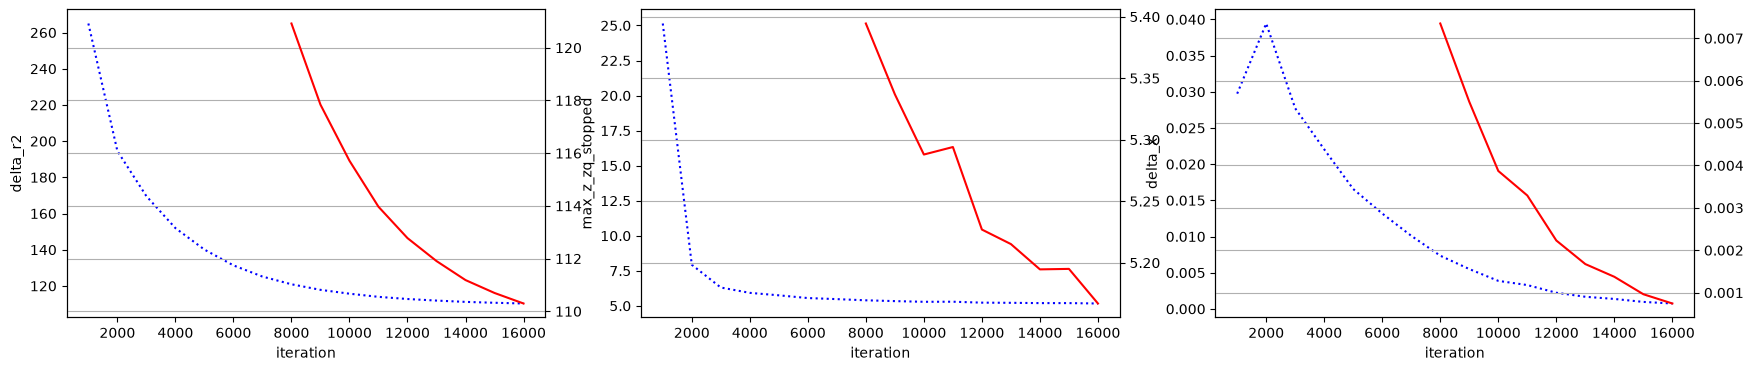

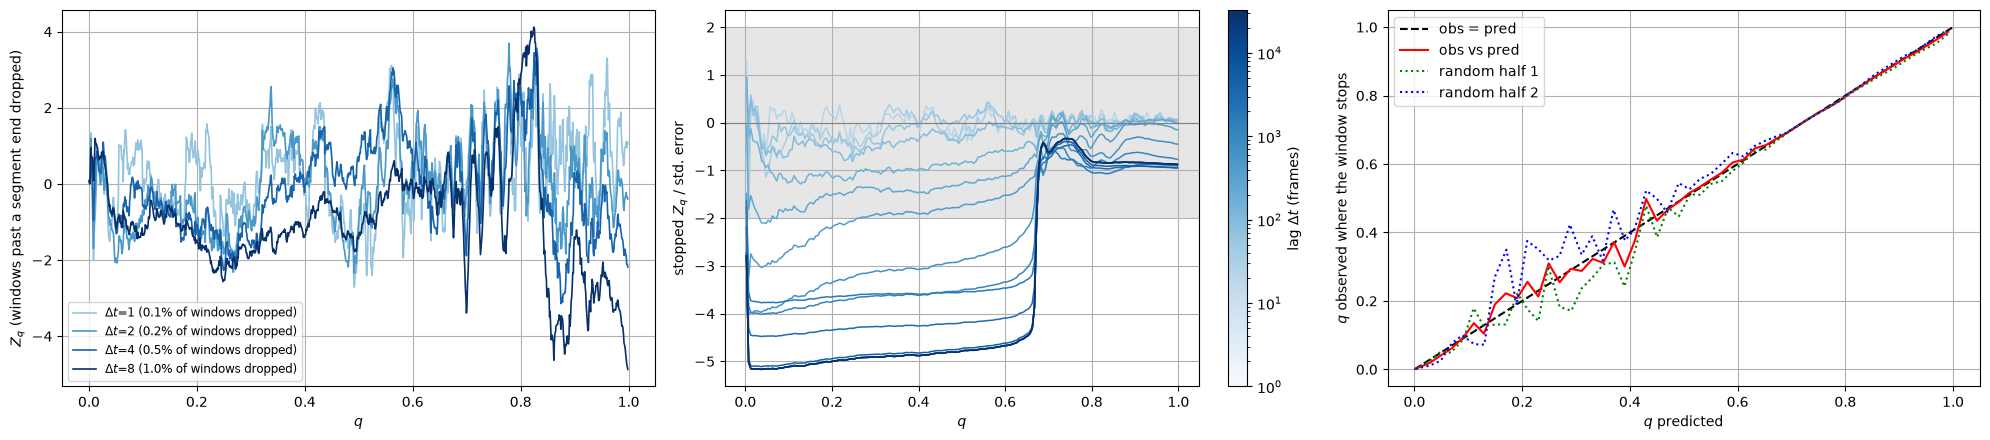

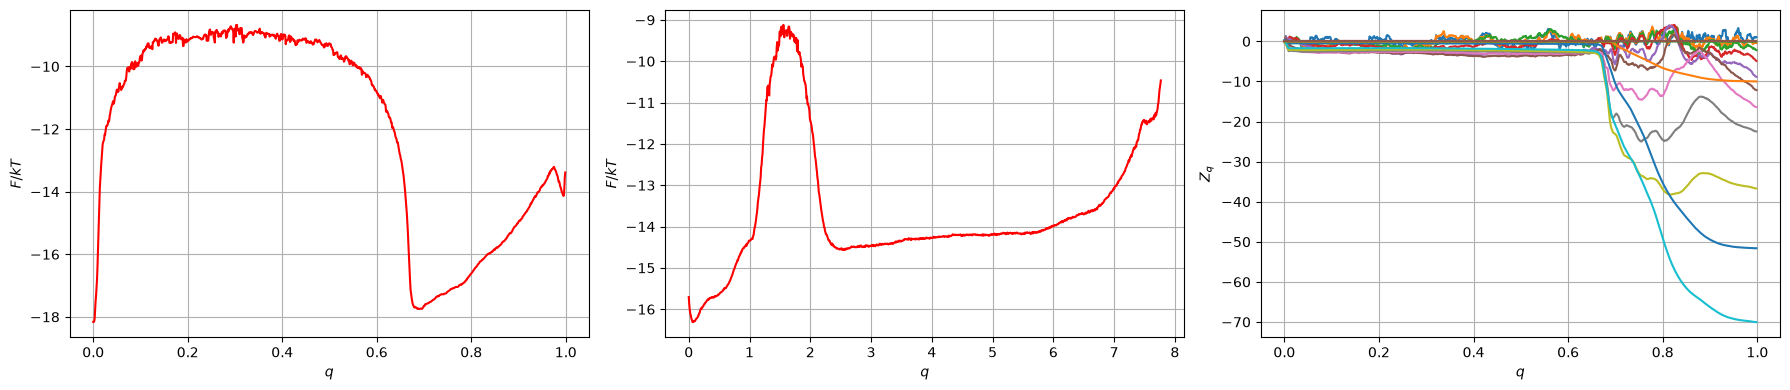

In [3]:
q_path = optimalrcs.CommittorNE(boundary0=data.boundary0, boundary1=data.boundary1,
                                i_traj=data.i_traj, t_traj=data.t_traj,
                                #path_weights=data.path_weights,      # MC weight of each frame's path
                                group_traj=data.group_traj)          # forward and mirrored piece of a path: treated as one
q_path.set_fixed_traj_length_trap(data.boundary0 | data.boundary1, 600)  # change??

cvs_path = [cp.asarray(y_path), cp.asarray(x_path)]
def comp_y_path():
    return cvs_path[np.random.randint(len(cvs_path))]

fit_kw = dict(ny=6, lazy_basis=True, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
np.random.seed(0)
cp.random.seed(0)

optimalrcs.envelope_scale = 1000000           # warm-up
q_path.fit_transform(comp_y_path, gamma=0.1, max_iter=1000, print_step=500, **fit_kw)
optimalrcs.envelope_scale = 0.01        # main fit
q_path.fit_transform(comp_y_path, gamma=0.1, max_iter=15000, print_step=1000, **fit_kw)

q_path.plots_metrics(['delta_r2', 'max_z_zq_stopped', 'delta_x'])
q_path.plots_tis()                        # stopped Z_q: the test for path data
q_path.plots_feps(delta_t_sim=0.002)      # with the path weights

In [5]:
# save in the format part 1 reads (FIRST_TRY_NPZ)
OUT_NPZ = f'{FIG}/committor_staple_p{PATHS_PER_ENSEMBLE}.npz'
np.savez(OUT_NPZ, r=q_path.r_traj.get(), X_all=data.X_all, i_traj=data.i_traj, t_traj=data.t_traj,
         path_weights=data.path_weights, boundary0=data.boundary0, boundary1=data.boundary1)
print('saved', OUT_NPZ)

saved figures/nb_zpot_short_traj/committor_staple_p10001st.npz
